# **TECNICATURA EN CIENCIA DE DATOS E INTELIGENCIA ARTIFICIAL**
# Práctica Profesionalizantes II- Año 2026
Alumnas:
*   Dolores Guadalupe Medina
*   Amalia Graciela Rodríguez



# **Base de datos: Arboles; mantenimiento; barrios y Densidad Poblacional**
Se pretende desarrollar un análisis de las tres bases de datos de manera que se pueda analizar la distribución espacial y el estado del arbolado urbano de la ciudad de Corrientes Capital, con el fin de identificar patrones de plantación por barrio, las prácticas de mantenimiento predominantes, y las zonas que requieren intervención prioritaria para la gestión y conservación del arbolado.
El conjunto de datos resume el inventario y el seguimiento del arbolado urbano de la ciudad, registrado a través de tres archivos relacionados entre sí mediante el identificador id_arbol (y nombre_barrio para la unión espacial):

1. arboles.csv — Fecha de publicación: 13 de marzo de 2024
Fecha de actualización: 22 de septiembre de 2025
nivel de árbol (inventario)
10.286 registros y 11 variables que describen la ubicación y el entorno físico de cada ejemplar:
id_arbol, direccion, tipo_vereda, lado_vereda, especie, tipo_tendido, distancia_entre_ar, distancia_al_muro, activo, lng, lat.
No presenta valores nulos en ninguna de sus columnas.

2. Seguimiento_Arboles.csv — Fecha de publicación: 13 de marzo de 2024
Fecha de actualización: 13 de agosto de 2025.  Fuente primaria:
Aplicacion de Arbolado Urbano de la Municipalidad de Corrientes.
nivel de seguimiento/mantenimiento: 12.597 registros y 17 variables que documentan cada intervención o control realizado sobre los árboles a lo largo del tiempo (un mismo árbol puede tener varios seguimientos):
id_seguimiento, id_arbol, fecha_hora, tipo_seguimiento, estado_salud, fuste, cazuela, ahuecamiento, inclinacion, altura, fase_vital, riesgo, levantamiento_vereda, tipo_tierra, tipo_calle, luz_led, prox_fecha_mante.
Tampoco presenta valores nulos.

3. barrios_de_la_ciudad.csv — nivel geográfico
140 registros y 6 variables con la delimitación de los barrios de la ciudad:
id_barrios, nombre_barrio, tipo_barrio, numero_ordenanza, sup_ha, the_geom (geometría en formato GeoJSON, usada para asignar cada árbol a su barrio mediante unión espacial).

4. Densidad_Poblacional.csv — Fuente primaria: Censo Nacional de Población, Hogares y Viviendas 2010 (INDEC).

Nivel de información territorial: 319 registros y 5 variables que describen la distribución de la población y su densidad en los radios censales de la ciudad de Corrientes: gid, total_poblacion, superficie, densidad_poblacion, the_geom.


In [ ]:
!pip install geopandas shapely fiona pyproj prince

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 88.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [prince]


In [ ]:
!pip install --upgrade jsonschema

In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import json
import sys

# Parche para corregir la incompatibilidad de jsonschema con altair/prince
try:
    import jsonschema.exceptions as jsonschema_exceptions
    import jsonschema
    jsonschema.exceptions = jsonschema_exceptions
    sys.modules['jsonschema.exceptions'] = jsonschema_exceptions
except ImportError:
    pass

import prince

from shapely.geometry import Point
from shapely.geometry import shape

In [ ]:
# Formato numérico argentino para todo lo que se imprime: 9.669 y 94,0% (no 9,669 y 94.0%).
def fmt_num(valor, decimales=0):
    """Punto para los miles, coma para los decimales."""
    texto = f"{valor:,.{decimales}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def fmt_pct(valor, decimales=1):
    return f"{fmt_num(valor, decimales)}%"


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

In [ ]:
import os
os.listdir("/content/drive/MyDrive/Prác.Prof.2-Estrada2026/")

['Seguimiento_Arboles.csv - Seguimiento_Arboles.csv.csv',
 'arboles.csv',
 'barrios_de_la_ciudad - barrios_de_la_ciudad.csv',
 'Densidad_Poblacional.csv']

In [ ]:
arboles = pd.read_csv(
    "/content/drive/MyDrive/Prác.Prof.2-Estrada2026/arboles.csv"
)

mantenimiento = pd.read_csv(
    "/content/drive/MyDrive/Prác.Prof.2-Estrada2026/Seguimiento_Arboles.csv - Seguimiento_Arboles.csv.csv"
)

barrios = pd.read_csv(
    "/content/drive/MyDrive/Prác.Prof.2-Estrada2026/barrios_de_la_ciudad - barrios_de_la_ciudad.csv"
)
Censo2010 = pd.read_csv(
    "/content/drive/MyDrive/Prác.Prof.2-Estrada2026/Densidad_Poblacional.csv"
)

# EXPLORACIÓN INICIAL DE DATOS- EDA

In [ ]:
arboles.head()

,id_arbol,direccion,tipo_vereda,lado_vereda,especie,tipo_tendido,distancia_entre_ar,distancia_al_muro,activo,lng,lat
0,8,San Juan 1278,Chica,Par,Crespón,Ninguno,5.0,1.0,True,-58.837098,-27.471856
1,16,San juan 1268,Chica,Impar,Crespón,Ninguno,5.0,1.0,True,-58.837121,-27.471663
2,17,Bolivar 1074,Mediana,Par,Paraíso,Media Tensión (Con Protección),5.0,2.0,True,-58.837567,-27.470889
3,18,Bolívar 1110,Grande,Par,Crespón,Preensamblado,3.0,1.0,True,-58.836943,-27.470922
4,19,Bolivar 1134,Grande,Par,Crespón,Preensamblado,5.0,2.0,True,-58.836670,-27.470951


In [ ]:
mantenimiento.head()

,id_seguimiento,id_arbol,fecha_hora,tipo_seguimiento,estado_salud,fuste,cazuela,ahuecamiento,inclinacion,altura,fase_vital,riesgo,levantamiento_vereda,tipo_tierra,tipo_calle,luz_led,prox_fecha_mante
0,1,8,5/11/2023 11:13:08,Plantacion,Bueno,Entre 0.10 y 0.40 m,Mediana,No,Sin inclinación,Menor a 5 m,Joven,Sin riesgo de caída,No,Arenosa,Asfalto,Si,2023-03-11
1,3,16,5/11/2023 11:25:05,Plantacion,Bueno,Menor a 0.10 m,Nivel del Piso,No,Sin inclinación,Menor a 5 m,Joven,Sin riesgo de caída,Considerable,Arenosa,Asfalto,Si,6/30/2023
2,4,17,5/11/2023 11:27:05,Plantacion,Bueno,Menor a 0.10 m,Chica,No,Sin inclinación,Menor a 5 m,Joven,Sin riesgo de caída,No,Limosa,Asfalto,Si,2023-09-10
3,5,18,5/11/2023 11:33:16,Plantacion,Bueno,Entre 0.10 y 0.40 m,Mediana,No,Sin inclinación,Menor a 5 m,Joven,Sin riesgo de caída,Considerable,Arenosa,Asfalto,Si,7/28/2023
4,6,19,5/11/2023 11:34:17,Plantacion,Bueno,Menor a 0.10 m,Nivel del Piso,No,Sin inclinación,Menor a 5 m,Joven,Sin riesgo de caída,No,Arenosa,Asfalto,Si,2023-11-05


In [ ]:
barrios.head()

,id_barrios,nombre_barrio,tipo_barrio,numero_ordenanza,sup_ha,the_geom
0,111,MERCEDITAS COLLANTES,ZONAS EN ORDENAMIENTO,S/D,488.214.568.517.694,"{""type"":""Polygon"",""coordinates"":[[[-58.7675801..."
1,116,SAMELA SUR,ZONAS EN ORDENAMIENTO,S/D,529.687.066.296.844,"{""type"":""Polygon"",""coordinates"":[[[-58.7560346..."
2,139,PARAJE PERICHON,BARRIOS POR ORDENANZA,6512/16,65.043.944.055.344,"{""type"":""Polygon"",""coordinates"":[[[-58.7452113..."
3,121,SANTA RITA SUR,ZONAS EN ORDENAMIENTO,S/D,164.841.752.627.056,"{""type"":""Polygon"",""coordinates"":[[[-58.7636221..."
4,122,SANTA RITA NORTE,ZONAS EN ORDENAMIENTO,S/D,194.290.336.891.252,"{""type"":""Polygon"",""coordinates"":[[[-58.7620038..."


In [ ]:
Censo2010.head()

,gid,varon,mujer,total_poblacion,hogares,viviendas_particulares,superficie,densidad_poblacion,the_geom
0,1,536.0,680.0,1216.0,454.0,410.0,12.96,94,"{""type"":""Polygon"",""coordinates"":[[[-58.8438409..."
1,2,371.0,472.0,843.0,312.0,330.0,22.87,37,"{""type"":""Polygon"",""coordinates"":[[[-58.8387404..."
2,3,499.0,660.0,1159.0,403.0,434.0,13.06,89,"{""type"":""Polygon"",""coordinates"":[[[-58.8440066..."
3,4,365.0,450.0,815.0,294.0,337.0,16.95,48,"{""type"":""Polygon"",""coordinates"":[[[-58.8438409..."
4,5,326.0,384.0,710.0,259.0,323.0,16.21,44,"{""type"":""Polygon"",""coordinates"":[[[-58.8478207..."


In [ ]:
print(arboles.shape)
print(mantenimiento.shape)
print(barrios.shape)
print(Censo2010.shape)

(10286, 11)
(12597, 17)
(140, 6)
(319, 9)


In [ ]:
#Veamos los nombres de las columnas
print(arboles.columns)
print(mantenimiento.columns)
print(barrios.columns)
print(Censo2010.columns)

Index(['id_arbol', 'direccion', 'tipo_vereda', 'lado_vereda', 'especie',
       'tipo_tendido', 'distancia_entre_ar', 'distancia_al_muro', 'activo',
       'lng', 'lat'],
      dtype='object')
Index(['id_seguimiento', 'id_arbol', 'fecha_hora', 'tipo_seguimiento',
       'estado_salud', 'fuste', 'cazuela', 'ahuecamiento', 'inclinacion',
       'altura', 'fase_vital', 'riesgo', 'levantamiento_vereda', 'tipo_tierra',
       'tipo_calle', 'luz_led', 'prox_fecha_mante'],
      dtype='object')
Index(['id_barrios', 'nombre_barrio', 'tipo_barrio', 'numero_ordenanza',
       'sup_ha', 'the_geom'],
      dtype='object')
Index(['gid', 'varon', 'mujer', 'total_poblacion', 'hogares',
       'viviendas_particulares', 'superficie', 'densidad_poblacion',
       'the_geom'],
      dtype='object')


EDA-ARBOLES


In [ ]:
#informaciòn de las columnas
arboles.info()
arboles.describe(include='all')
arboles.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10286 entries, 0 to 10285
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_arbol            10286 non-null  int64  
 1   direccion           10286 non-null  object 
 2   tipo_vereda         10286 non-null  object 
 3   lado_vereda         10286 non-null  object 
 4   especie             10286 non-null  object 
 5   tipo_tendido        10286 non-null  object 
 6   distancia_entre_ar  10286 non-null  float64
 7   distancia_al_muro   10286 non-null  float64
 8   activo              10286 non-null  bool   
 9   lng                 10286 non-null  float64
 10  lat                 10286 non-null  float64
dtypes: bool(1), float64(4), int64(1), object(5)
memory usage: 813.8+ KB


,0
id_arbol,0
direccion,0
tipo_vereda,0
lado_vereda,0
especie,0
tipo_tendido,0
distancia_entre_ar,0
distancia_al_muro,0
activo,0
lng,0


ninguna de las 11 variables presenta datos nulos, ya que todas registran un valor de 0. Esto indica que la base de datos está completa y no será necesario realizar tratamientos de imputación o eliminación de registros por datos faltantes antes de comenzar el análisis.
1 variable entera (int64): id_arbol, que identifica de manera única a cada árbol.
4 variables numéricas (float64): distancia_entre_ar, distancia_al_muro, lng y lat, que contienen información sobre distancias y coordenadas geográficas.
5 variables categóricas (object): direccion, tipo_vereda, lado_vereda, especie y tipo_tendido, que describen las características del árbol y su entorno.
1 variable booleana (bool): activo, que indica si el árbol se encuentra registrado como activo.

In [ ]:
arboles.duplicated().sum()

np.int64(0)

no existen filas duplicadas en el conjunto de datos.


In [ ]:
arboles["id_arbol"].nunique()

10286

In [ ]:
arboles.isna().sum()

,0
id_arbol,0
direccion,0
tipo_vereda,0
lado_vereda,0
especie,0
tipo_tendido,0
distancia_entre_ar,0
distancia_al_muro,0
activo,0
lng,0


EDA-MANTENIMIENTO


In [ ]:
mantenimiento.head()

mantenimiento.info()

mantenimiento.describe(include='all')

mantenimiento.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12597 entries, 0 to 12596
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   id_seguimiento        12597 non-null  int64 
 1   id_arbol              12597 non-null  int64 
 2   fecha_hora            12597 non-null  object
 3   tipo_seguimiento      12597 non-null  object
 4   estado_salud          12597 non-null  object
 5   fuste                 12597 non-null  object
 6   cazuela               12597 non-null  object
 7   ahuecamiento          12597 non-null  object
 8   inclinacion           12597 non-null  object
 9   altura                12597 non-null  object
 10  fase_vital            12597 non-null  object
 11  riesgo                12597 non-null  object
 12  levantamiento_vereda  12597 non-null  object
 13  tipo_tierra           12597 non-null  object
 14  tipo_calle            12597 non-null  object
 15  luz_led               12597 non-null

,0
id_seguimiento,0
id_arbol,0
fecha_hora,0
tipo_seguimiento,0
estado_salud,0
fuste,0
cazuela,0
ahuecamiento,0
inclinacion,0
altura,0


In [ ]:
mantenimiento.duplicated().sum()

np.int64(0)

In [ ]:

#  Convertir la columna 'fecha_hora' a tipo datetime
mantenimiento['fecha_hora'] = pd.to_datetime(mantenimiento['fecha_hora'], errors='coerce')

#  Convertir 'prox_fecha_mante' a tipo datetime (pd.to_datetime detecta automáticamente los formatos mixtos)
mantenimiento['prox_fecha_mante'] = pd.to_datetime(mantenimiento['prox_fecha_mante'], errors='coerce')


# Verificación de los tipos de datos actualizados
print(mantenimiento[['fecha_hora', 'prox_fecha_mante']].dtypes)
mantenimiento.head()

fecha_hora          datetime64[ns]
prox_fecha_mante    datetime64[ns]
dtype: object


,id_seguimiento,id_arbol,fecha_hora,tipo_seguimiento,estado_salud,fuste,cazuela,ahuecamiento,inclinacion,altura,fase_vital,riesgo,levantamiento_vereda,tipo_tierra,tipo_calle,luz_led,prox_fecha_mante
0,1,8,2023-05-11 11:13:08,Plantacion,Bueno,Entre 0.10 y 0.40 m,Mediana,No,Sin inclinación,Menor a 5 m,Joven,Sin riesgo de caída,No,Arenosa,Asfalto,Si,2023-03-11
1,3,16,2023-05-11 11:25:05,Plantacion,Bueno,Menor a 0.10 m,Nivel del Piso,No,Sin inclinación,Menor a 5 m,Joven,Sin riesgo de caída,Considerable,Arenosa,Asfalto,Si,NaT
2,4,17,2023-05-11 11:27:05,Plantacion,Bueno,Menor a 0.10 m,Chica,No,Sin inclinación,Menor a 5 m,Joven,Sin riesgo de caída,No,Limosa,Asfalto,Si,2023-09-10
3,5,18,2023-05-11 11:33:16,Plantacion,Bueno,Entre 0.10 y 0.40 m,Mediana,No,Sin inclinación,Menor a 5 m,Joven,Sin riesgo de caída,Considerable,Arenosa,Asfalto,Si,NaT
4,6,19,2023-05-11 11:34:17,Plantacion,Bueno,Menor a 0.10 m,Nivel del Piso,No,Sin inclinación,Menor a 5 m,Joven,Sin riesgo de caída,No,Arenosa,Asfalto,Si,2023-11-05


##EDA-BARRIOS

In [ ]:
barrios.head()

barrios.info()

barrios.describe(include='all')

barrios.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   id_barrios        140 non-null    int64 
 1   nombre_barrio     140 non-null    object
 2   tipo_barrio       140 non-null    object
 3   numero_ordenanza  140 non-null    object
 4   sup_ha            137 non-null    object
 5   the_geom          140 non-null    object
dtypes: int64(1), object(5)
memory usage: 6.7+ KB


,0
id_barrios,0
nombre_barrio,0
tipo_barrio,0
numero_ordenanza,0
sup_ha,3
the_geom,0


sup_ha:tiene 3 valores faltantes.Se procede a revisar qué barrios son y si la superficie puede recuperarse de otra fuente o calcularse a partir de la geometría.

In [ ]:
barrios[barrios["sup_ha"].isna()][[
    "id_barrios",
    "nombre_barrio",
    "tipo_barrio",
    "numero_ordenanza",
    "sup_ha"
]]

,id_barrios,nombre_barrio,tipo_barrio,numero_ordenanza,sup_ha
8,154,JOSE MARIA PAZ,BARRIOS POR ORDENANZA,7503/24,NaN
27,153,ASENTAMIENTO PIRAYUI SUR,ASENTAMIENTOS INFORMALES,S/D,NaN
139,300,SANTA CATALINA,BARRIOS POR ORDENANZA,S/D,NaN


In [ ]:
barrios.duplicated().sum()

np.int64(0)

no existen filas completamente duplicadas

In [ ]:
barrios["id_barrios"].duplicated().sum()

np.int64(2)

Hay 2 registros que tienen un id_barrios repetido

In [ ]:
barrios[barrios["id_barrios"].duplicated(keep=False)].sort_values("id_barrios")

,id_barrios,nombre_barrio,tipo_barrio,numero_ordenanza,sup_ha,the_geom
135,23,COLLANTES,BARRIOS POR ORDENANZA,1967/88,153.264.823.698.885,"{""type"":""Polygon"",""coordinates"":[[[-58.7789566..."
46,23,COLLANTES,BARRIOS POR ORDENANZA,1967/88,153.264.823.698.885,"{""type"":""Polygon"",""coordinates"":[[[-58.7814445..."
41,56,MOLINA PUNTA,BARRIOS POR ORDENANZA,1967/89,541.179.075.671.406,"{""type"":""Polygon"",""coordinates"":[[[-58.7848129..."
24,56,MOLINA PUNTA,BARRIOS POR ORDENANZA,1967/89,541.179.075.671.406,"{""type"":""Polygon"",""coordinates"":[[[-58.7700021..."


**Corrección:** los dos `id_barrios` repetidos (23-COLLANTES y 56-MOLINA PUNTA) tienen el
mismo `sup_ha`, `tipo_barrio` y `numero_ordenanza` en ambas filas, pero **geometrías
(`the_geom`) distintas**: no es un error de carga, son dos fragmentos de polígono
separados del mismo barrio (un barrio con territorio partido en dos partes). Si acá
descartáramos una de las dos filas con `drop_duplicates`, perderíamos ese fragmento: los
árboles ubicados en esa parte del barrio dejarían de caer dentro de su polígono en el
cruce espacial, y `sup_geometria_ha` quedaría subestimada para esos dos barrios.

Por eso **no** se elimina ninguna fila acá. La resolución correcta —unir (`dissolve`) las
dos geometrías de cada barrio repetido en una sola— se hace más abajo, una vez que
`the_geom` ya se convirtió en geometría real.

(La verificación de que ya no quedan `id_barrios` duplicados se hace más abajo, después
de unir las geometrías — ver la celda de `dissolve`.)

In [ ]:
# Convertir the_geom en geometría
import json
from shapely.geometry import shape

barrios["geometry"] = barrios["the_geom"].apply(
    lambda x: shape(json.loads(x)) if isinstance(x, str) else shape(x)
)

In [ ]:
#Comprobamos
barrios[["id_barrios", "nombre_barrio", "geometry"]].head()

,id_barrios,nombre_barrio,geometry
0,111,MERCEDITAS COLLANTES,"POLYGON ((-58.7675801297845 -27.4610932362064,..."
1,116,SAMELA SUR,"POLYGON ((-58.7560346147132 -27.4970467785613,..."
2,139,PARAJE PERICHON,"POLYGON ((-58.7452113773831 -27.4040047608691,..."
3,121,SANTA RITA SUR,"POLYGON ((-58.7636221731499 -27.4880477053514,..."
4,122,SANTA RITA NORTE,"POLYGON ((-58.7620038184015 -27.4822011046832,..."


**Unificación de geometrías duplicadas (Collantes y Molina Punta).** En vez de descartar
una de las dos filas de cada barrio repetido, unimos sus geometrías con `dissolve` para
conservar el territorio completo de ambos fragmentos.

In [ ]:
import geopandas as gpd

gdf_barrios_raw = gpd.GeoDataFrame(barrios, geometry="geometry", crs="EPSG:4326")

# dissolve agrupa por id_barrios y une (unary_union) las geometrías de cada grupo;
# como el resto de las columnas es idéntico entre las filas duplicadas, aggfunc="first"
# no pierde información.
barrios = (
    gdf_barrios_raw
    .dissolve(by="id_barrios", aggfunc="first")
    .reset_index()
)

print("Filas en 'barrios' después de unir geometrías duplicadas:", len(barrios))
print("id_barrios duplicados restantes:", barrios["id_barrios"].duplicated().sum())

barrios[barrios["id_barrios"].isin([23, 56])][["id_barrios", "nombre_barrio", "geometry"]]


Filas en 'barrios' después de unir geometrías duplicadas: 138
id_barrios duplicados restantes: 0


,id_barrios,nombre_barrio,geometry
22,23,COLLANTES,"MULTIPOLYGON (((-58.77896 -27.46078, -58.77896..."
50,56,MOLINA PUNTA,"MULTIPOLYGON (((-58.77056 -27.45345, -58.7701 ..."


In [ ]:
#Crear el GeoDataFrame
import geopandas as gpd

gdf_barrios = gpd.GeoDataFrame(
    barrios,
    geometry="geometry"
)

In [ ]:
gdf_barrios = gdf_barrios.set_crs("EPSG:4326")

In [ ]:
barrios.dtypes

,0
id_barrios,int64
geometry,geometry
nombre_barrio,object
tipo_barrio,object
numero_ordenanza,object
sup_ha,object
the_geom,object


In [ ]:
#Revisamos la columna sup_ha
barrios["sup_ha"].head(10)

,sup_ha
0,15.718.404.549.062
1,111.521.732.293.385
2,113.822.077.891.742
3,585.819.879.493.183
4,412.434.794.844.079
5,102.603.897.187.912
6,381.357.616.190.356
7,513.250.443.345.452
8,583.573.089.423.367
9,122.186.788.782.201


In [ ]:
print(barrios["sup_ha"].head(10).to_list())

print(barrios["sup_ha"].str.count(r"\.").value_counts())

print(barrios[["nombre_barrio", "sup_ha"]].head(20).to_string(index=False))

['15.718.404.549.062', '111.521.732.293.385', '113.822.077.891.742', '585.819.879.493.183', '412.434.794.844.079', '102.603.897.187.912', '381.357.616.190.356', '513.250.443.345.452', '583.573.089.423.367', '122.186.788.782.201']
sup_ha
4.0    135
Name: count, dtype: int64
      nombre_barrio              sup_ha
       17 DE agosto  15.718.404.549.062
         3 DE abril 111.521.732.293.385
         9 DE julio 113.822.077.891.742
             ALDANA 585.819.879.493.183
        ALTA GRACIA 412.434.794.844.079
              ANAHI 102.603.897.187.912
ANTARTIDA ARGENTINA 381.357.616.190.356
              APIPE 513.250.443.345.452
            ARAZATI 583.573.089.423.367
        AYUDA MUTUA 122.186.788.782.201
           BANCARIO 413.312.730.622.012
       BAÑADO NORTE  65.615.617.886.669
           BELGRANO 461.975.021.170.213
   BERON DE ASTRADA 325.392.502.255.415
  CACIQUE CANINDEYU 359.871.156.488.264
          CAMBA CUA 112.587.784.238.675
             CENTRO 781.520.187.233.539
      

**Corrección de orden:** esta celda se movió antes de crear `gdf_barrios` (más abajo).
En el orden original, `gdf_barrios = barrios.copy()` se ejecutaba *antes* de reparar
`sup_ha`, así que `gdf_barrios` (y por lo tanto `gdf_barrios_m`, que se deriva de él) se
quedaba con el `sup_ha` roto (separador de miles mal puesto). `sup_geometria_ha` no se ve
afectado porque se calcula desde la geometría, no desde `sup_ha` — pero la tabla que
compara ambas columnas mostraba un `sup_ha` inconsistente. Reparando `sup_ha` antes de
sacar la copia, `gdf_barrios`, `gdf_barrios_m` y la tabla comparativa quedan con el valor
correcto.

In [ ]:
# Corregiremos la superficie por hectarea de cada barrio
import numpy as np

def corregir_sup(valor):
    if isinstance(valor, str):
        partes = valor.split(".")
        return float(partes[0] + "." + "".join(partes[1:]))
    return np.nan

barrios["sup_ha"] = barrios["sup_ha"].apply(corregir_sup)

In [ ]:
import geopandas as gpd

gdf_barrios = gpd.GeoDataFrame(
    barrios.copy(),
    geometry="geometry",
    crs="EPSG:4326"
)

In [ ]:
import geopandas as gpd

#Probando: Como las geometrías están en coordenadas geográficas EPSG:4326, no debemos calcular el área directamente en ese CRS.

#Podemos proyectarlas a un CRS apropiado para Corrientes y calcular:
gdf = gdf_barrios.to_crs("EPSG:32721")

In [ ]:
#Verificamos
print(type(gdf_barrios))
print(gdf_barrios.crs)

<class 'geopandas.geodataframe.GeoDataFrame'>
EPSG:4326


In [ ]:
#Reproyectamos para calcular las superficies
gdf_barrios_m = gdf_barrios.to_crs("EPSG:32721")

In [ ]:
#alculamos el área de los barrios
gdf_barrios_m["sup_geometria_ha"] = (
    gdf_barrios_m.geometry.area / 10000
)


In [ ]:
superficies_barrios = gdf_barrios_m[
    [
        "id_barrios",
        "nombre_barrio",
        "sup_ha",
        "sup_geometria_ha"
    ]
].sort_values(
    "sup_geometria_ha",
    ascending=False
)

superficies_barrios

,id_barrios,nombre_barrio,sup_ha,sup_geometria_ha
131,139,PARAJE PERICHON,65.043.944.055.344,724.479768
133,150,PASO MARTINEZ,196.213.920.520.105,194.683001
39,44,JOSE MARIA PONCE,170.390.504.531.416,187.917430
132,140,ZONA SUR PIRAYUI,180.290.046.831.616,178.832809
0,1,17 DE agosto,15.718.404.549.062,155.972096
...,...,...,...,...
10,11,BANCARIO,413.312.730.622.012,4.101418
89,96,TAMBOR DE TACUARI,207.831.527.686.776,4.067892
134,152,92 VIV SALVADOR MIQUERI,401.945.039.337.399,4.015926
117,125,ASENTAMIENTO ERAGIA,308.607.437.249.552,3.062109


In [ ]:
# Verifiquemos el tipo de dato sup_geometria_ha y comprobemos que las superficies tengan sentido
superficies_barrios["sup_geometria_ha"].dtype
superficies_barrios["sup_geometria_ha"].describe()

,sup_geometria_ha
count,138.000000
mean,54.392565
std,70.765535
min,2.858405
25%,16.465573
50%,40.615031
75%,68.962488
max,724.479768


**Decisión metodológica:** de acá en adelante, todo indicador "por hectárea" (densidad
de árboles, etc.) se calcula con `sup_geometria_ha` y no con `sup_ha`. `sup_ha` queda
en el DataFrame solo como referencia/control (por ejemplo para la comparación de la
celda anterior), pero no se usa en ningún cálculo posterior.

In [ ]:
# A partir de acá usamos sup_geometria_ha (calculada desde la geometría real de cada
# barrio) como la superficie de referencia para todo cálculo "por hectárea" que siga,
# en vez de sup_ha (que venía del CSV con errores de formato y con 3 nulos). La
# incorporamos a 'barrios', que es el DataFrame que se usa en el resto del notebook.
barrios = barrios.merge(
    gdf_barrios_m[["id_barrios", "sup_geometria_ha"]],
    on="id_barrios",
    how="left"
)

print("Barrios con sup_geometria_ha calculada:", barrios["sup_geometria_ha"].notna().sum(), "de", len(barrios))
barrios[["nombre_barrio", "sup_ha", "sup_geometria_ha"]].head()


Barrios con sup_geometria_ha calculada: 138 de 138


,nombre_barrio,sup_ha,sup_geometria_ha
0,17 DE agosto,15.718405,155.972096
1,3 DE abril,111.521732,110.706711
2,9 DE julio,113.822078,112.945996
3,ALDANA,585.819879,58.131723
4,ALTA GRACIA,412.434795,40.888842


Hay 138 geometrías con superficie calculable, pero solamente 137 valores de sup_ha registrados.

Esto es importante porque NaN en sup_ha no significa necesariamente que falte geometría.
Media: 53,96 ha- Mediana: 40,13 ha

Esto indica que existen algunos barrios con superficies considerablemente mayores que elevan la media.

El máximo es: 724,48 ha

mientras que el 75 % de los barrios tiene una superficie de 68,96 ha o menos.

Por lo tanto, la distribución está sesgada hacia valores altos.

In [ ]:
# --- Normalización de nombres de barrios para visualización ---
# Un único criterio: inicial mayúscula en cada palabra, conectores (de, del, la...) en
# minúscula y números romanos intactos ("Juan XXIII", "Pio X"). La inicial se pone en la
# primera LETRA, así un nombre que empieza con signo ("¿SUR") queda "¿Sur".
import re

_CONECTORES = {"de", "del", "la", "las", "los", "el", "y"}
_ROMANO = re.compile(r"^(?=[IVXLC])(X{0,3})(IX|IV|V?I{0,3})$")


def _capitalizar(parte):
    minusculas = parte.lower()
    for k, caracter in enumerate(minusculas):
        if caracter.isalpha():
            return minusculas[:k] + caracter.upper() + minusculas[k + 1:]
    return minusculas


def normalizar_nombre_barrio(nombre):
    if not isinstance(nombre, str):
        return nombre
    palabras = []
    for k, palabra in enumerate(nombre.strip().split()):
        if _ROMANO.match(palabra.upper()):
            palabras.append(palabra.upper())
        elif k > 0 and palabra.lower() in _CONECTORES:
            palabras.append(palabra.lower())
        else:
            palabras.append("-".join(_capitalizar(p) for p in palabra.split("-")))
    return " ".join(palabras)


barrios["nombre_barrio"] = barrios["nombre_barrio"].map(normalizar_nombre_barrio)
# Refrescar también la tabla geográfica ya construida para que los cruces posteriores
# utilicen el mismo nombre visible.
gdf_barrios["nombre_barrio"] = gdf_barrios["nombre_barrio"].map(normalizar_nombre_barrio)
gdf_barrios_m["nombre_barrio"] = gdf_barrios_m["nombre_barrio"].map(normalizar_nombre_barrio)

barrios[["id_barrios", "nombre_barrio"]].head()



,id_barrios,nombre_barrio
0,1,17 de Agosto
1,2,3 de Abril
2,3,9 de Julio
3,4,Aldana
4,5,Alta Gracia


##Preprocesamiento/Transformación de datos espaciales

In [ ]:
#La base de datos barrios ya la había convertido en un GeoDataframe, solo verificamor que realmente es un GeoDataFrame
print(type(gdf_barrios))
print(gdf_barrios.crs)
print(gdf_barrios.geometry.geom_type.value_counts())

<class 'geopandas.geodataframe.GeoDataFrame'>
EPSG:4326
Polygon         136
MultiPolygon      2
Name: count, dtype: int64


In [ ]:
# --- CORRECCIÓN: 'gdf_arboles' se usaba en el sjoin sin haber sido creado ---
# Construimos el GeoDataFrame de árboles a partir de lng/lat (WGS84 = EPSG:4326),
# que es el sistema de coordenadas en el que vienen los datos.
gdf_arboles = gpd.GeoDataFrame(
    arboles.copy(),
    geometry=gpd.points_from_xy(arboles["lng"], arboles["lat"]),
    crs="EPSG:4326"
)

print(type(gdf_arboles))
print(gdf_arboles.crs)
print("Árboles con geometría construida:", len(gdf_arboles))


<class 'geopandas.geodataframe.GeoDataFrame'>
EPSG:4326
Árboles con geometría construida: 10286


In [ ]:
#Asigna automáticamente cada arbol a un barrio
arboles_barrios = gpd.sjoin(
    gdf_arboles,
    gdf_barrios[["nombre_barrio","geometry"]],
    how="left",
    predicate="within"
)


In [ ]:
#Verificamos
arboles_barrios[[
    "id_arbol",
    "nombre_barrio",
    "lat",
    "lng"
]].head()

,id_arbol,nombre_barrio,lat,lng
0,8,Centro,-27.471856,-58.837098
1,16,Centro,-27.471663,-58.837121
2,17,La Cruz,-27.470889,-58.837567
3,18,Centro,-27.470922,-58.836943
4,19,Centro,-27.470951,-58.836670


**Antes de unir `arboles` y `mantenimiento`:** el merge que sigue usa `arboles` como tabla base (`how="left"`), por lo que cualquier `id_arbol` presente en `mantenimiento` pero ausente en `arboles.csv` queda excluido del resultado sin ningún aviso. Descartar esos registros es razonable (no hay forma de ubicarlos ni de asignarles barrio o especie), pero hay que cuantificarlos explícitamente antes de tirarlos: si no se documenta cuántos son, el análisis subestima el volumen real de seguimientos sin que quede registro de por qué.

In [ ]:
mantenimiento["tipo_seguimiento"].value_counts(dropna=False)

,count
tipo_seguimiento,
Registro de Arbol,9125
Plantacion,2391
Mantenimiento,881
Inspeccion,72
Redireccionamiento,64
Extraccion,51
Tala,7
Saneamiento,6


In [ ]:
# Cuantificamos los seguimientos que apuntan a árboles inexistentes en arboles.csv
# ANTES de descartarlos con el merge, para dejar la exclusión documentada.
seguimientos_huerfanos = mantenimiento[
    ~mantenimiento["id_arbol"].isin(arboles["id_arbol"])
]

n_huerfanos = len(seguimientos_huerfanos)
pct_huerfanos = n_huerfanos / len(mantenimiento) * 100

print(
    f"Registros de seguimiento sin árbol asociado en arboles.csv: "
    f"{n_huerfanos} de {len(mantenimiento)} ({pct_huerfanos:.1f}%)"
)
print("Se descartan en el merge siguiente (how='left' con 'arboles' como base).")

seguimientos_huerfanos["tipo_seguimiento"].value_counts()

Registros de seguimiento sin árbol asociado en arboles.csv: 2209 de 12597 (17.5%)
Se descartan en el merge siguiente (how='left' con 'arboles' como base).


,count
tipo_seguimiento,
Registro de Arbol,2166
Plantacion,42
Tala,1


In [ ]:
# Unimos con la base de datos de mantenimiento
df = pd.merge(
    arboles,
    mantenimiento,
    on="id_arbol",
    how="left"
)

In [ ]:
# Incorporamos el barrio de cada árbol (calculado antes con el sjoin espacial) a "df"
df = df.merge(
    arboles_barrios[["id_arbol", "nombre_barrio"]],
    on="id_arbol",
    how="left"
)

print("Árboles sin barrio asignado (fuera de todos los polígonos):", df["nombre_barrio"].isna().sum())
df[["id_arbol", "nombre_barrio"]].head()

Árboles sin barrio asignado (fuera de todos los polígonos): 618


,id_arbol,nombre_barrio
0,8,Centro
1,16,Centro
2,17,La Cruz
3,18,Centro
4,19,Centro


In [ ]:
# --- Indicador de cobertura (Advertencia de la devolución) ---
# La exclusión de árboles sin barrio y de barrios sin registros está acordada
# con la cátedra, pero el indicador tiene que quedar visible y no implícito.
total_arboles_padron = len(arboles)
arboles_geolocalizados = df["nombre_barrio"].notna().sum()  # árboles que cayeron dentro de algún polígono
barrios_con_registros = df["nombre_barrio"].nunique()
total_barrios = barrios.shape[0]

pct_geolocalizados = arboles_geolocalizados / total_arboles_padron * 100

print("=== Cobertura del cruce espacial árbol → barrio ===")
print(f"{arboles_geolocalizados:,} de {total_arboles_padron:,} árboles geolocalizados ({pct_geolocalizados:.1f}%)")
print(f"{barrios_con_registros} de {total_barrios} barrios con registros")
print(f"Árboles fuera de todos los polígonos: {total_arboles_padron - arboles_geolocalizados:,}")
print(f"Barrios sin ningún árbol asignado: {total_barrios - barrios_con_registros}")
print("(Exclusión acordada con la cátedra; se documenta para que quede explícita)")


=== Cobertura del cruce espacial árbol → barrio ===
9,770 de 10,286 árboles geolocalizados (95.0%)
107 de 138 barrios con registros
Árboles fuera de todos los polígonos: 516
Barrios sin ningún árbol asignado: 31
(Exclusión acordada con la cátedra; se documenta para que quede explícita)


In [ ]:
# Confirmamos que el merge descartó exactamente los seguimientos huérfanos detectados arriba
print(f"mantenimiento: {len(mantenimiento)} filas")
print(f"df (tras el merge): {df['id_seguimiento'].notna().sum()} seguimientos conservados")
print(
    f"Seguimientos excluidos por no tener árbol en arboles.csv: "
    f"{n_huerfanos} ({pct_huerfanos:.1f}% del total de mantenimiento)"
)

mantenimiento: 12597 filas
df (tras el merge): 10388 seguimientos conservados
Seguimientos excluidos por no tener árbol en arboles.csv: 2209 (17.5% del total de mantenimiento)


##**ESTADÍSTICA DESCRIPTIVA- Arboles**

In [ ]:
len(arboles)

10286

In [ ]:
#CANTIDAD DE ESPECIES
arboles["especie"].nunique()

86

In [ ]:
# ESPECIES MÁS FRECUENTES
arboles["especie"].value_counts().head(10)

,count
especie,
Fresno,1394
Palmera,1346
Lapacho rosado,1234
Pata de Buey,570
Ibirá Pitá,358
Lapacho,314
Naranjo agrio,300
Falso paraiso,281
Jacarandá,281


In [ ]:
df[['lat', 'lng']].describe()

,lat,lng
count,10388.000000,10388.000000
mean,-27.474833,-58.832608
std,0.016568,0.021225
min,-27.531695,-58.856140
25%,-27.476643,-58.846385
50%,-27.470860,-58.837333
75%,-27.465466,-58.828159
max,-27.296925,-58.689607


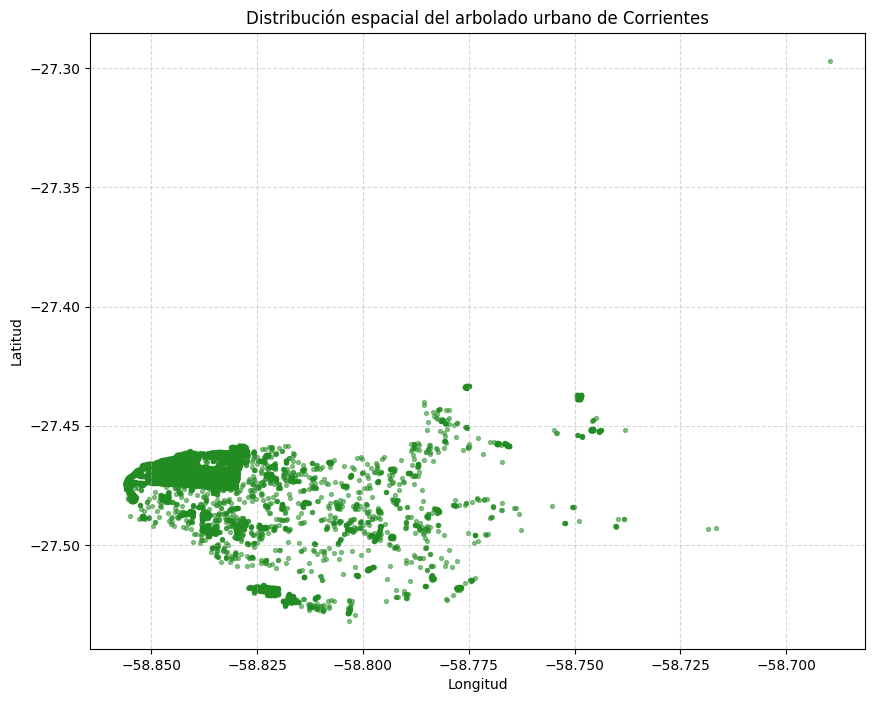

In [ ]:
#Observamos como están distribuidos los arboles en la ciudad

plt.figure(figsize=(10,8))

plt.scatter(
    df["lng"],      # Longitud (eje X)
    df["lat"],      # Latitud (eje Y)
    s=8,                  # Tamaño de los puntos
    alpha=0.5,            # Transparencia
    color="forestgreen"
)

plt.title("Distribución espacial del arbolado urbano de Corrientes")
plt.xlabel("Longitud")
plt.ylabel("Latitud")

plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

In [ ]:
import folium
from folium.plugins import HeatMap

mapa = folium.Map(
    location=[df["lat"].mean(), df["lng"].mean()],
    zoom_start=13
)

HeatMap(df[["lat", "lng"]].values.tolist(), radius=12).add_to(mapa)

mapa

Las zonas con colores rojo y amarillo indicarán mayor concentración de árboles, mientras que las verdes o azules mostrarán menor densidad.

## **¿Qué barrios tienen más arboles plantados?**

Top 15 barrios con mayor cantidad de árboles:
           Barrio  Cantidad de árboles
        Camba Cua                 2545
           Centro                  990
          La Cruz                  872
          Arazati                  765
        La Rosada                  697
           Aldana                  644
         Deportes                  537
   Santa Catalina                  243
         Libertad                  241
      Pedro Ferre                  138
       Juan XXIII                  105
       9 de Julio                  104
Cacique Canindeyu                   85
            Pio X                   78
     17 de Agosto                   69


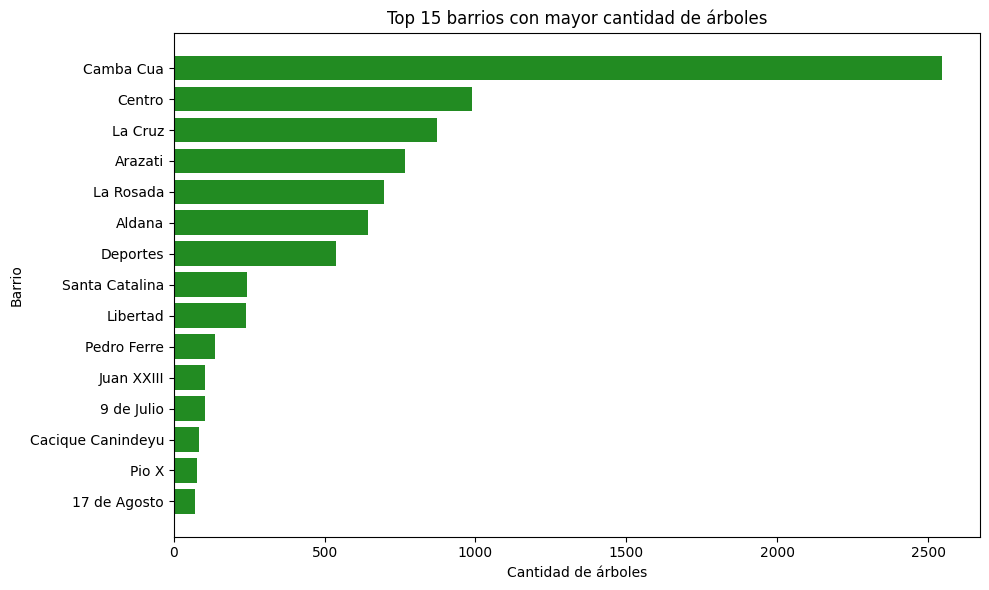

In [ ]:
# Top 15 barrios con mayor cantidad de árboles
top_15_barrios = (
    arboles_barrios["nombre_barrio"]
    .value_counts()
    .head(15)
    .rename_axis("Barrio")
    .reset_index(name="Cantidad de árboles")
)

# Ordenar de mayor a menor cantidad
top_15_barrios = top_15_barrios.sort_values(
    "Cantidad de árboles",
    ascending=False
)

# Mostrar tabla
print("Top 15 barrios con mayor cantidad de árboles:")
print(top_15_barrios.to_string(index=False))

# Gráfico
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.barh(
    top_15_barrios["Barrio"],
    top_15_barrios["Cantidad de árboles"],
    color='forestgreen'
)
plt.xlabel("Cantidad de árboles")
plt.ylabel("Barrio")
plt.title("Top 15 barrios con mayor cantidad de árboles")
plt.gca().invert_yaxis() # Para mostrar el barrio con más árboles arriba
plt.tight_layout()
plt.show()

In [ ]:
print(f"El barrio con más árboles plantados es '{top_15_barrios.iloc[0]['Barrio']}' "
      f"con {top_15_barrios.iloc[0]['Cantidad de árboles']} árboles.")

El barrio con más árboles plantados es 'Camba Cua' con 2545 árboles.


##**¿Qué tipos de mantenimiento aparecen con mayor frecuencia?**

In [ ]:
# Cantidad de registros en mantenimiento
total_seguimientos = len(mantenimiento)

# Cantidad de árboles únicos
total_arboles = mantenimiento["id_arbol"].nunique()

print("Total de seguimientos:", total_seguimientos)
print("Total de árboles únicos:", total_arboles)

Total de seguimientos: 12597
Total de árboles únicos: 12491


In [ ]:
diferencia = total_seguimientos - total_arboles

print("Registros adicionales por seguimientos múltiples:", diferencia)

Registros adicionales por seguimientos múltiples: 106


In [ ]:
# Detectamos arboles con más de un seguimiento
seguimientos_por_arbol = (
    mantenimiento["id_arbol"]
    .value_counts()
)

arboles_multiples = seguimientos_por_arbol[
    seguimientos_por_arbol > 1
]

print("Árboles con más de un seguimiento:", len(arboles_multiples))

Árboles con más de un seguimiento: 102


In [ ]:
# comprobar que fecha_hora sea realmente fecha
mantenimiento["fecha_hora"] = pd.to_datetime(
    mantenimiento["fecha_hora"],
    errors="coerce"
)

print(mantenimiento["fecha_hora"].dtype)

datetime64[ns]


In [ ]:
# ordenamos los seguimientos por fecha
mantenimiento = mantenimiento.sort_values(
    ["id_arbol", "fecha_hora"]
)

In [ ]:
#quedamos con el ultimo seguimiento realizado a cada arbol
mantenimiento_actual = (
    mantenimiento
    .sort_values("fecha_hora")
    .drop_duplicates(
        subset="id_arbol",
        keep="last"
    )
)

In [ ]:
# Filtrar registros de mantenimiento excluyendo el alta/registro inicial
df_mantenimiento_real = mantenimiento[
    mantenimiento['tipo_seguimiento'] != 'Registro de Arbol'
]

# Calcular el mantenimiento real más frecuente
tipo_mas_frecuente = df_mantenimiento_real['tipo_seguimiento'].mode()[0]
print(f"El mantenimiento más frecuente es: {tipo_mas_frecuente}") # Plantación y Mantenimiento

El mantenimiento más frecuente es: Plantacion


In [ ]:
# Identificar seguimientos sin coincidencia en el padrón de árboles
seguimientos_huerfanos = mantenimiento[~mantenimiento['id_arbol'].isin(arboles['id_arbol'])]
cant_huerfanos = len(seguimientos_huerfanos)
pct_huerfanos = (cant_huerfanos / len(mantenimiento)) * 100

# # Mostrar en el tablero (Streamlit)
# st.warning(f"⚠️ Se descartaron {cant_huerfanos:,} registros de seguimiento ({pct_huerfanos:.1f}%) por hacer referencia a ID de árboles inexistentes en el padrón.")

# Realizar el merge limpio
df_merged = mantenimiento.merge(arboles, on='id_arbol', how='inner')

In [ ]:
# Asegurar que fecha_hora sea tipo datetime
mantenimiento['fecha_hora'] = pd.to_datetime(mantenimiento['fecha_hora'])

# Ordenar por fecha y quedarse con el último registro por árbol
ultimo_seguimiento = (
    mantenimiento.sort_values('fecha_hora')
    .groupby('id_arbol')
    .last()
    .reset_index()
)

# Cruzar con el padrón de árboles único
df_estado_actual = arboles.merge(ultimo_seguimiento, on='id_arbol', how='left')

total_arboles_unicos = df_estado_actual['id_arbol'].nunique()
print(f"Total de árboles únicos evaluados: {total_arboles_unicos}") # 10.286

Total de árboles únicos evaluados: 10286


In [ ]:
mantenimiento[mantenimiento["tipo_seguimiento"] != 'Registro de Arbol']["tipo_seguimiento"].value_counts()

,count
tipo_seguimiento,
Plantacion,2391
Mantenimiento,881
Inspeccion,72
Redireccionamiento,64
Extraccion,51
Tala,7
Saneamiento,6


In [ ]:
frecuencia = mantenimiento[mantenimiento['tipo_seguimiento'] != 'Registro de Arbol']['tipo_seguimiento'].value_counts()

porcentaje = (
    mantenimiento["tipo_seguimiento"]
    .value_counts(normalize=True)*100
)

tabla = pd.DataFrame({
    "Frecuencia": frecuencia,
    "Porcentaje": porcentaje.round(2)
})

tabla

,Frecuencia,Porcentaje
tipo_seguimiento,,
Extraccion,51.0,0.40
Inspeccion,72.0,0.57
Mantenimiento,881.0,6.99
Plantacion,2391.0,18.98
Redireccionamiento,64.0,0.51
Registro de Arbol,NaN,72.44
Saneamiento,6.0,0.05
Tala,7.0,0.06


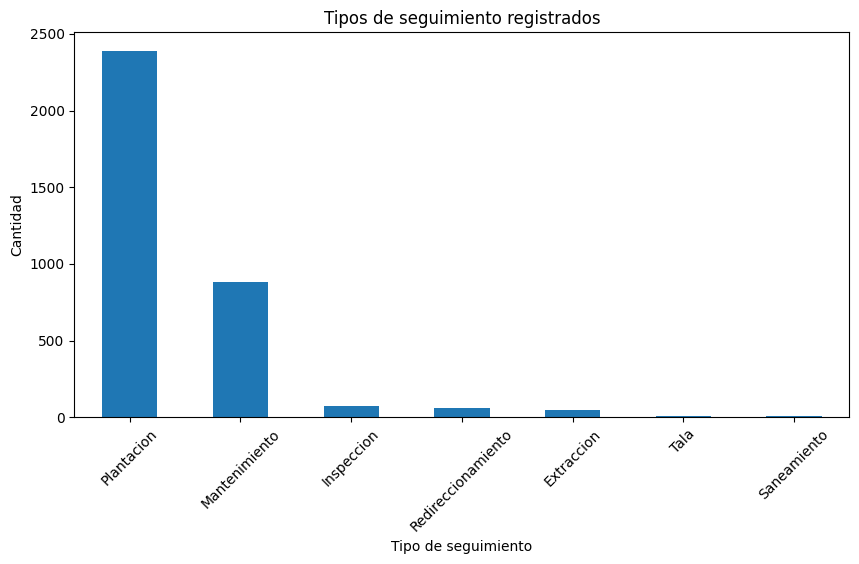

In [ ]:
import matplotlib.pyplot as plt

#Observamos la cantidad de tipos de seguimientos registrados

mantenimiento[mantenimiento["tipo_seguimiento"] != 'Registro de Arbol']["tipo_seguimiento"].value_counts().plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Tipos de seguimiento registrados")
plt.xlabel("Tipo de seguimiento")
plt.ylabel("Cantidad")
plt.xticks(rotation=45)

plt.show()

## Zona Norte vs Zona Sur ¿hay barrios o sectores con mayor necesidad de intervención?

El cruce de la Avenida 3 de Abril y Rioja (zona histórica que marca el límite sur del casco céntrico) tiene una latitud aproximada de -27.472°.Utilizando este punto como línea divisoria imaginaria, se divide la ciudad en dos zonas bien definidas:Zona Norte (Centro/Casco Histórico): Todo lo que se extiende hacia el Río Paraná (Latitudes entre -27.45° y -27.471°).Zona Sur (Periferia): Los barrios y sectores que se expanden hacia las Rutas 12 y 5 (Latitudes de -27.473° en adelante).

In [ ]:
lat_divisoria = -27.472

In [ ]:
# Creamos una nueva columna en Df
df["zona"] = df["lat"].apply(
    lambda x: "Zona Norte" if x >= lat_divisoria else "Zona Sur"
)

In [ ]:
df["zona"].value_counts()

,count
zona,
Zona Norte,5959
Zona Sur,4429


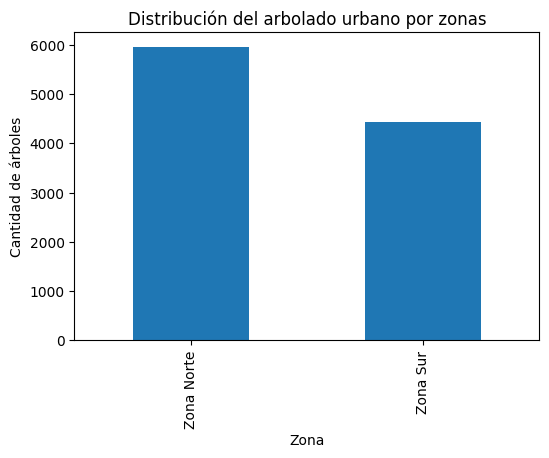

In [ ]:

conteo = df["zona"].value_counts()

plt.figure(figsize=(6,4))
conteo.plot(kind="bar")

plt.title("Distribución del arbolado urbano por zonas")
plt.xlabel("Zona")
plt.ylabel("Cantidad de árboles")

plt.show()

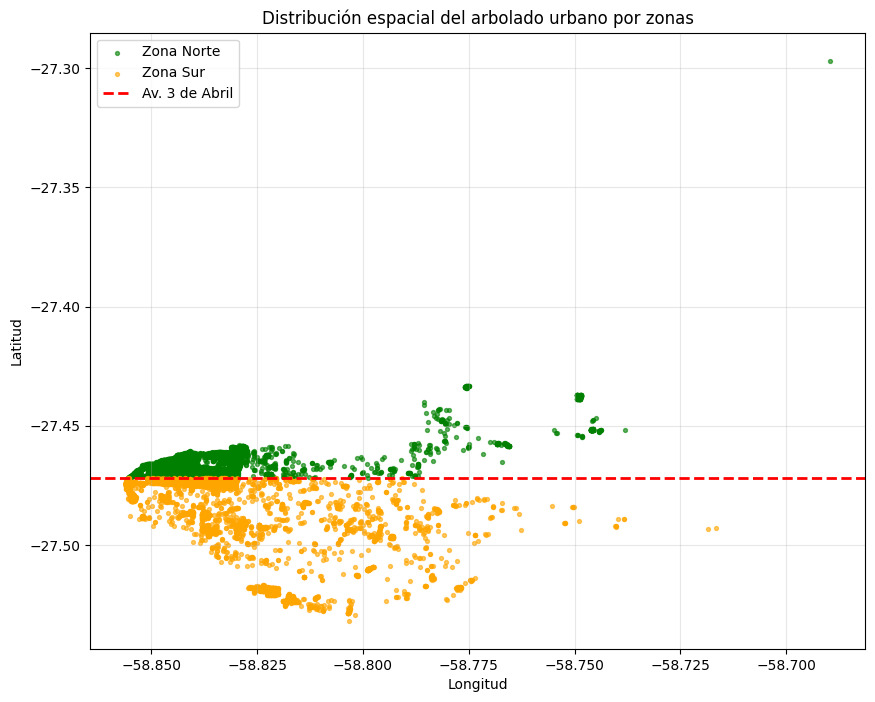

In [ ]:


plt.figure(figsize=(10,8))

colores = {
    "Zona Norte": "green",
    "Zona Sur": "orange"
}

for zona, color in colores.items():

    datos = df[df["zona"] == zona]

    plt.scatter(
        datos["lng"],
        datos["lat"],
        s=8,
        alpha=0.6,
        label=zona,
        color=color
    )

# Línea divisoria (Av. 3 de Abril)
plt.axhline(
    y=-27.472,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Av. 3 de Abril"
)

plt.title("Distribución espacial del arbolado urbano por zonas")
plt.xlabel("Longitud")
plt.ylabel("Latitud")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Estas variables permiten identificar árboles que potencialmente requieren atención:

riesgo
estado_salud
inclinacion
ahuecamiento
levantamiento_vereda
fase_vital

In [ ]:
df["riesgo"].value_counts()

,count
riesgo,
Sin riesgo de caída,8139
Arbol parasitado (con especies vegetales),1673
Arbol parasitado (insectos),122
Arbol parasitado ( con hongos ),115
Con riesgo de caída (bajo),111
Con riesgo de caída (moderado),86
Con riesgo de caída (alto),67
Otros parásitos (fuste),31
Otros parásitos (ramas),29


In [ ]:
#Distribución por zona
riesgo_zona = pd.crosstab(df["zona"], df["riesgo"])

riesgo_zona

riesgo,Arbol parasitado ( con hongos ),Arbol parasitado (con especies vegetales),Arbol parasitado (insectos),Arbol parasitado (otros animales),Con riesgo de caída (alto),Con riesgo de caída (bajo),Con riesgo de caída (moderado),Otros parásitos (fuste),Otros parásitos (ramas),Otros parásitos (raíz ),Sin riesgo de caída
zona,,,,,,,,,,,
Zona Norte,98,1062,74,2,46,56,53,18,12,7,4531
Zona Sur,17,611,48,1,21,55,33,13,17,5,3608


In [ ]:
#Analizamos el estado de salud
pd.crosstab(
    df["zona"],
    df["estado_salud"]
)

estado_salud,Bueno,Malo,Muerto,Regular
zona,,,,
Zona Norte,5381,92,45,441
Zona Sur,4174,62,19,174


In [ ]:
#Levantamiento de vereda
pd.crosstab(
    df["zona"],
    df["levantamiento_vereda"]
)

levantamiento_vereda,Considerable,Leve,No
zona,,,
Zona Norte,957,274,4728
Zona Sur,1047,140,3242


In [ ]:
#Ahuecamiento
pd.crosstab(
    df["zona"],
    df["ahuecamiento"]
)

ahuecamiento,Alto,Bajo,Base,Mayor al 50% del diámetro del tronco,Menor al 50% del diámetro del tronco,Moderado,No,Si,Tronco
zona,,,,,,,,,
Zona Norte,287,43,37,27,37,86,5340,70,32
Zona Sur,313,36,11,25,21,199,3794,19,11


In [ ]:
pd.crosstab(
    df["zona"],
    df["inclinacion"]
)

inclinacion,Leve,Moderado,Pronunciado,Sin inclinación
zona,,,,
Zona Norte,1565,309,136,3949
Zona Sur,1111,180,91,3047


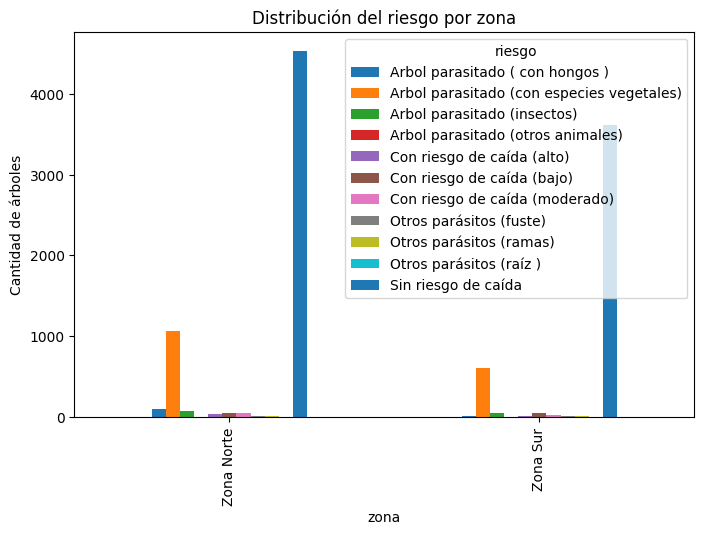

In [ ]:
riesgo_zona.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Distribución del riesgo por zona")
plt.ylabel("Cantidad de árboles")
plt.show()

# **Análisis Bivariado**

In [ ]:
# Riesgo vs Estado de Salud
tabla_salud = pd.crosstab(
    df["riesgo"],
    df["estado_salud"]
)

tabla_salud

estado_salud,Bueno,Malo,Muerto,Regular
riesgo,,,,
Arbol parasitado ( con hongos ),32,14,0,69
Arbol parasitado (con especies vegetales),1480,40,10,143
Arbol parasitado (insectos),55,21,1,45
Arbol parasitado (otros animales),2,0,0,1
Con riesgo de caída (alto),17,21,16,13
Con riesgo de caída (bajo),69,3,2,37
Con riesgo de caída (moderado),44,10,3,29
Otros parásitos (fuste),10,9,1,11
Otros parásitos (ramas),23,2,0,4


In [ ]:
# Porcentaje por fila
tabla_salud_pct = pd.crosstab(
    df["riesgo"],
    df["estado_salud"],
    normalize="index"
) * 100

tabla_salud_pct.round(2)

estado_salud,Bueno,Malo,Muerto,Regular
riesgo,,,,
Arbol parasitado ( con hongos ),27.83,12.17,0.00,60.00
Arbol parasitado (con especies vegetales),88.46,2.39,0.60,8.55
Arbol parasitado (insectos),45.08,17.21,0.82,36.89
Arbol parasitado (otros animales),66.67,0.00,0.00,33.33
Con riesgo de caída (alto),25.37,31.34,23.88,19.40
Con riesgo de caída (bajo),62.16,2.70,1.80,33.33
Con riesgo de caída (moderado),51.16,11.63,3.49,33.72
Otros parásitos (fuste),32.26,29.03,3.23,35.48
Otros parásitos (ramas),79.31,6.90,0.00,13.79


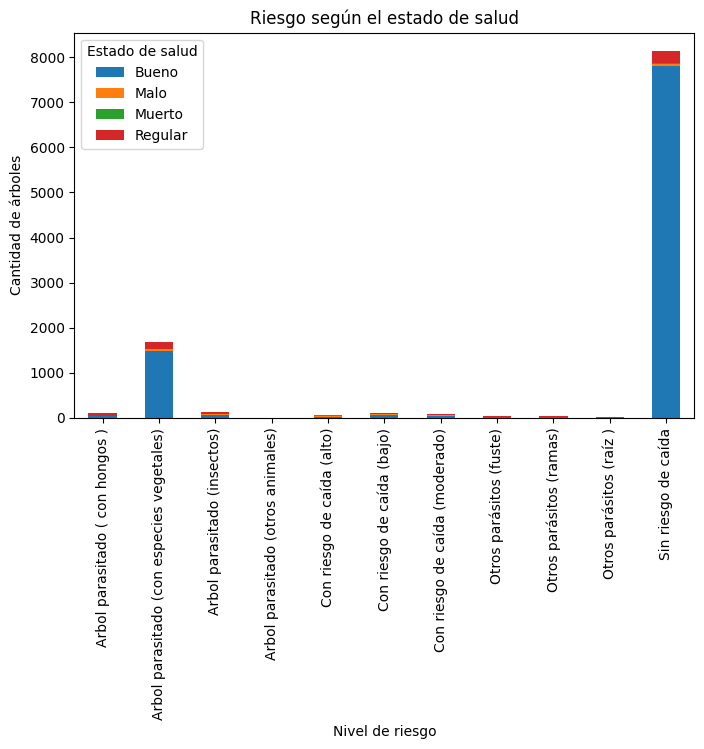

In [ ]:
#Observamos el riesgo de los arboles de acuerdo a su estado de salud

tabla_salud.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5)
)

plt.title("Riesgo según el estado de salud")
plt.xlabel("Nivel de riesgo")
plt.ylabel("Cantidad de árboles")
plt.legend(title="Estado de salud")

plt.show()

In [ ]:
# Prueba Chi Cuadrado
from scipy.stats import chi2_contingency

chi2, p, gl, esperados = chi2_contingency(tabla_salud)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"Valor p: {p:.4f}")

Chi-cuadrado: 3052.11
Valor p: 0.0000


Estadístico Chi-cuadrado (χ²): 3052.11
Valor p: < 0.0001

Como el valor p es inferior a 0.05, se rechaza la hipótesis nula de independencia. Esto indica que existe una asociación estadísticamente significativa entre el nivel de riesgo y el estado de salud de los árboles.

En otras palabras, el riesgo de un árbol no es independiente de su estado de salud. La evidencia estadística sugiere que el estado sanitario influye en la clasificación del riesgo, por lo que los árboles con un estado de salud más desfavorable tienden a presentar niveles de riesgo más elevados.

In [ ]:
# Riesgo vs Inclinaciòn
tabla_inclinacion = pd.crosstab(
    df["riesgo"],
    df["inclinacion"]
)

tabla_inclinacion

inclinacion,Leve,Moderado,Pronunciado,Sin inclinación
riesgo,,,,
Arbol parasitado ( con hongos ),33,8,3,71
Arbol parasitado (con especies vegetales),838,99,41,695
Arbol parasitado (insectos),36,15,6,65
Arbol parasitado (otros animales),1,0,0,2
Con riesgo de caída (alto),16,19,21,11
Con riesgo de caída (bajo),41,22,22,26
Con riesgo de caída (moderado),28,21,16,21
Otros parásitos (fuste),9,6,3,13
Otros parásitos (ramas),4,4,3,18


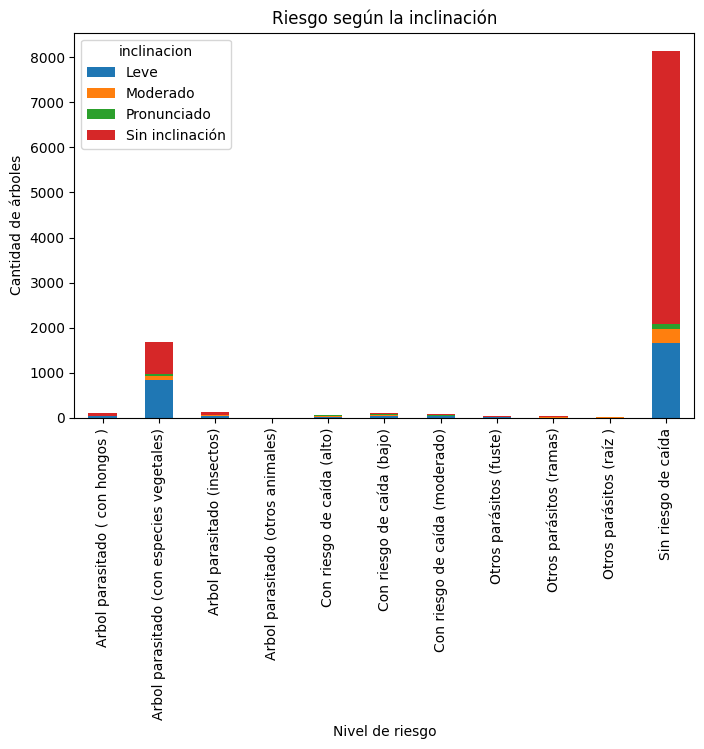

In [ ]:
# Riesgo vs Inclinaciòn
tabla_inclinacion.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5)
)

plt.title("Riesgo según la inclinación")
plt.xlabel("Nivel de riesgo")
plt.ylabel("Cantidad de árboles")

plt.show()

In [ ]:
# Chi Cuadrado
from scipy.stats import chi2_contingency

chi2, p, gl, esperados = chi2_contingency(tabla_inclinacion)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"Grados de libertad: {gl}")
print(f"Valor p: {p:.6f}")

Chi-cuadrado: 1651.23
Grados de libertad: 30
Valor p: 0.000000


χ² = 1651.23
Grados de libertad = 30
Valor p < 0.001

Como el valor p es menor que 0.05, se rechaza la hipótesis nula de independencia. Esto indica que existe una asociación estadísticamente significativa entre el nivel de riesgo y la inclinación de los árboles.

En consecuencia, la inclinación constituye un factor relacionado con la clasificación del riesgo del arbolado urbano. La distribución observada sugiere que las diferentes categorías de inclinación no se presentan de la misma manera en todos los niveles de riesgo, lo que evidencia que ambas variables están vinculadas.

In [ ]:
# Riesgo vs Ahuecamiento
tabla_ahuecamiento = pd.crosstab(
    df["riesgo"],
    df["ahuecamiento"]
)

tabla_ahuecamiento

ahuecamiento,Alto,Bajo,Base,Mayor al 50% del diámetro del tronco,Menor al 50% del diámetro del tronco,Moderado,No,Si,Tronco
riesgo,,,,,,,,,
Arbol parasitado ( con hongos ),5,4,1,3,4,3,93,2,0
Arbol parasitado (con especies vegetales),311,21,15,11,9,93,1160,37,16
Arbol parasitado (insectos),9,2,2,2,6,2,96,3,0
Arbol parasitado (otros animales),0,0,0,0,0,0,3,0,0
Con riesgo de caída (alto),19,3,2,7,2,0,30,3,1
Con riesgo de caída (bajo),5,8,3,8,5,13,67,2,0
Con riesgo de caída (moderado),8,2,1,11,6,5,45,6,2
Otros parásitos (fuste),2,1,1,1,2,2,14,6,2
Otros parásitos (ramas),2,0,0,1,1,2,22,0,1


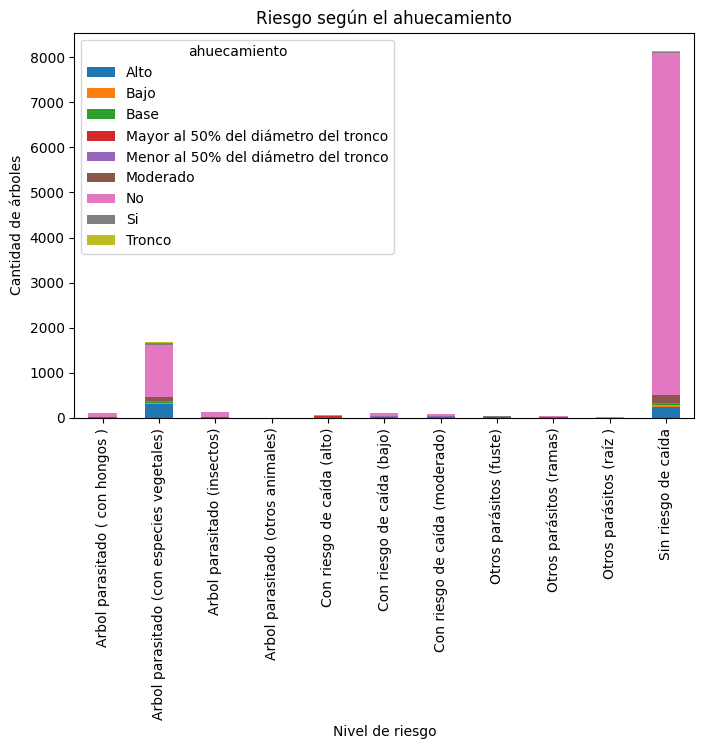

In [ ]:
tabla_ahuecamiento.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5)
)

plt.title("Riesgo según el ahuecamiento")
plt.xlabel("Nivel de riesgo")
plt.ylabel("Cantidad de árboles")

plt.show()

In [ ]:
# Riesgo vs Ahuecamiento
from scipy.stats import chi2_contingency

chi2, p, gl, esperados = chi2_contingency(tabla_ahuecamiento)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"Grados de libertad: {gl}")
print(f"Valor p: {p:.6f}")

Chi-cuadrado: 2104.44
Grados de libertad: 80
Valor p: 0.000000


Dado que el valor p es significativamente menor que 0.05, se rechaza la hipótesis nula de independencia. Esto indica que existe una asociación estadísticamente significativa entre el nivel de riesgo y el ahuecamiento de los árboles.

En términos prácticos, la distribución de las categorías de ahuecamiento no es la misma para todos los niveles de riesgo, lo que sugiere que ambas variables están relacionadas. Por lo tanto, el ahuecamiento constituye un aspecto relevante para la evaluación del estado estructural del arbolado y debe ser considerado en la planificación de las tareas de mantenimiento e intervención.

In [ ]:
# Riesgo vs Levantamiento de vereda
tabla_vereda = pd.crosstab(
    df["riesgo"],
    df["levantamiento_vereda"]
)

tabla_vereda

levantamiento_vereda,Considerable,Leve,No
riesgo,,,
Arbol parasitado ( con hongos ),19,12,84
Arbol parasitado (con especies vegetales),622,71,980
Arbol parasitado (insectos),21,5,96
Arbol parasitado (otros animales),0,0,3
Con riesgo de caída (alto),23,8,36
Con riesgo de caída (bajo),45,10,56
Con riesgo de caída (moderado),30,9,47
Otros parásitos (fuste),12,3,16
Otros parásitos (ramas),4,1,24


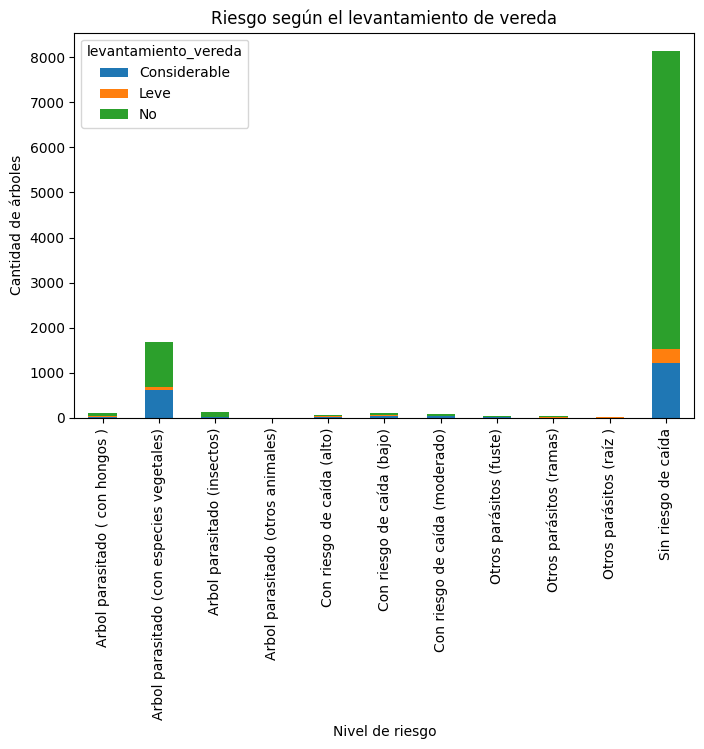

In [ ]:
tabla_vereda.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5)
)

plt.title("Riesgo según el levantamiento de vereda")
plt.xlabel("Nivel de riesgo")
plt.ylabel("Cantidad de árboles")

plt.show()

In [ ]:
from scipy.stats import chi2_contingency

chi2, p, gl, esperados = chi2_contingency(tabla_vereda)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"Grados de libertad: {gl}")
print(f"Valor p: {p:.6f}")

Chi-cuadrado: 599.57
Grados de libertad: 20
Valor p: 0.000000


Dado que el valor p es inferior a 0.05, se rechaza la hipótesis nula de independencia. En consecuencia, existe evidencia estadísticamente significativa de una asociación entre el nivel de riesgo y el levantamiento de vereda.

Este resultado indica que la distribución de las categorías de levantamiento de vereda difiere según el nivel de riesgo del árbol, lo que sugiere que ambas variables están relacionadas. Por ello, el levantamiento de veredas constituye un aspecto relevante a considerar en la evaluación del estado del arbolado urbano y en la planificación de acciones de mantenimiento.

In [ ]:
# Riesgo vs Fase Vital
tabla_fase = pd.crosstab(
    df["riesgo"],
    df["fase_vital"]
)

tabla_fase

fase_vital,Añoso,Decrepito,Joven,Maduro,Recien Implantado
riesgo,,,,,
Arbol parasitado ( con hongos ),21,4,25,61,4
Arbol parasitado (con especies vegetales),956,22,160,519,16
Arbol parasitado (insectos),20,5,43,51,3
Arbol parasitado (otros animales),1,0,1,1,0
Con riesgo de caída (alto),40,8,4,15,0
Con riesgo de caída (bajo),51,5,16,39,0
Con riesgo de caída (moderado),48,4,9,24,1
Otros parásitos (fuste),15,0,5,11,0
Otros parásitos (ramas),6,0,7,15,1


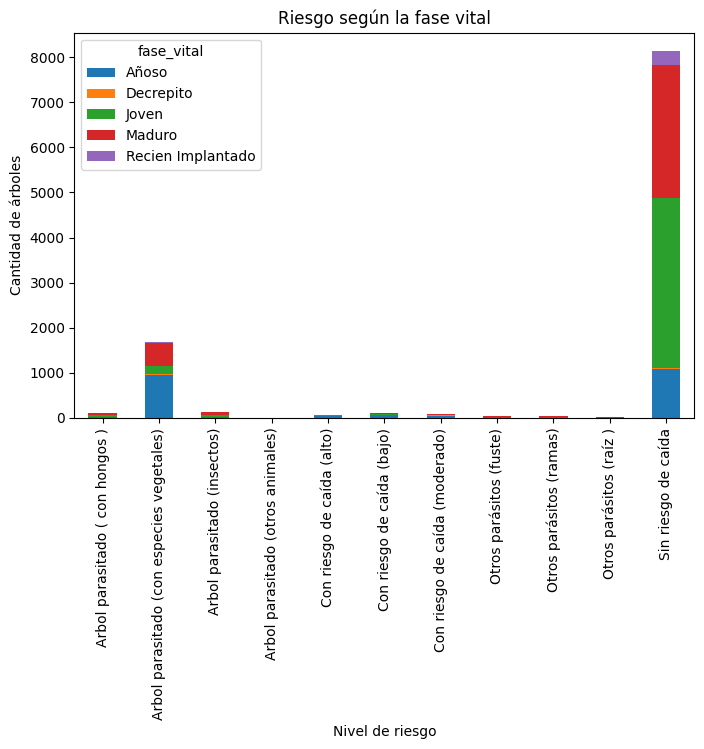

In [ ]:
tabla_fase.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5)
)

plt.title("Riesgo según la fase vital")
plt.xlabel("Nivel de riesgo")
plt.ylabel("Cantidad de árboles")

plt.show()

In [ ]:
from scipy.stats import chi2_contingency

chi2, p, gl, esperados = chi2_contingency(tabla_fase)

print(f"Chi-cuadrado: {chi2:.2f}")
print(f"Grados de libertad: {gl}")
print(f"Valor p: {p:.6f}")

Chi-cuadrado: 2220.14
Grados de libertad: 40
Valor p: 0.000000


Dado que el valor p es inferior a 0.05, se rechaza la hipótesis nula de independencia. En consecuencia, existe evidencia estadísticamente significativa de una asociación entre el nivel de riesgo y la fase vital de los árboles.

Este resultado indica que la distribución de las distintas fases vitales no es la misma para todos los niveles de riesgo, lo que sugiere que ambas variables están relacionadas. Por lo tanto, la fase vital constituye un factor relevante para la evaluación del estado del arbolado urbano y para la planificación de acciones de mantenimiento.

## **¿Hay barrios con mayor necesidad de intervención?**

### Corrección (Advertencia 5 de la devolución)

El índice de intervención original se calculaba sobre `df`, que tiene una fila por cada
combinación árbol × seguimiento (hay árboles con más de un seguimiento registrado). Eso
infla el denominador `total_arboles` y, si un árbol tiene seguimientos con riesgo distinto,
lo cuenta más de una vez con valores contradictorios.

La corrección: se usa `df_estado_actual`, construido antes a partir del **último
seguimiento de cada árbol según `fecha_hora`** (una fila por árbol = estado actual), y se le
incorpora el barrio.

In [ ]:
# Incorporamos el barrio al último seguimiento de cada árbol (nivel árbol, sin duplicar filas)
df_estado_actual = df_estado_actual.merge(
    arboles_barrios[["id_arbol", "nombre_barrio"]],
    on="id_arbol",
    how="left"
)

print("Filas en df_estado_actual:", len(df_estado_actual))
print("Árboles únicos:", df_estado_actual["id_arbol"].nunique())
assert len(df_estado_actual) == df_estado_actual["id_arbol"].nunique(), \
    "df_estado_actual debe tener una sola fila por árbol"


Filas en df_estado_actual: 10286
Árboles únicos: 10286


In [ ]:
tabla_riesgo_barrio = pd.crosstab(df_estado_actual["nombre_barrio"], df_estado_actual["riesgo"])
tabla_riesgo_barrio


riesgo,Arbol parasitado ( con hongos ),Arbol parasitado (con especies vegetales),Arbol parasitado (insectos),Arbol parasitado (otros animales),Con riesgo de caída (alto),Con riesgo de caída (bajo),Con riesgo de caída (moderado),Otros parásitos (fuste),Otros parásitos (ramas),Otros parásitos (raíz ),Sin riesgo de caída
nombre_barrio,,,,,,,,,,,
17 de Agosto,0,6,0,0,1,0,0,0,3,0,59
3 de Abril,0,2,0,0,0,1,1,0,0,0,15
9 de Julio,0,59,1,0,0,0,2,0,0,1,41
Aldana,0,226,4,1,1,1,1,0,1,0,409
Alta Gracia,0,5,0,0,0,0,0,0,0,0,9
...,...,...,...,...,...,...,...,...,...,...,...
Villa Chiquita,1,13,0,0,0,0,1,0,0,1,15
Villa Raquel,0,8,0,0,1,0,0,0,0,0,2
Virgen de los Dolores,0,0,0,0,0,0,0,0,0,0,1


In [ ]:
# Resumen por barrio: total de ÁRBOLES (no de filas árbol×seguimiento) y árboles con riesgo alto,
# calculado sobre el último seguimiento de cada árbol.
riesgo_alto_col = "Con riesgo de caída (alto)"

resumen_barrio = pd.DataFrame({
    "total_arboles": df_estado_actual.groupby("nombre_barrio")["id_arbol"].nunique()
})

resumen_barrio["riesgo_alto"] = (
    df_estado_actual[df_estado_actual["riesgo"] == riesgo_alto_col]
    .groupby("nombre_barrio")["id_arbol"]
    .nunique()
)
resumen_barrio["riesgo_alto"] = resumen_barrio["riesgo_alto"].fillna(0).astype(int)
resumen_barrio["pct_riesgo_alto"] = (
    resumen_barrio["riesgo_alto"] / resumen_barrio["total_arboles"] * 100
).round(2)

resumen_barrio.sort_values("pct_riesgo_alto", ascending=False).head(15)


,total_arboles,riesgo_alto,pct_riesgo_alto
nombre_barrio,,,
Villa Celia,5,1,20.00
Asentamiento Punta Taitalo,30,4,13.33
Anahi,9,1,11.11
Parque Balneario Molina Punta,10,1,10.00
Bejarano,10,1,10.00
Villa Raquel,11,1,9.09
Ciudad de Arequipa,15,1,6.67
Santa Rosa,18,1,5.56
Popular,21,1,4.76


### Corrección (Advertencias 6 y 7 de la devolución)

Con solo 78 (a nivel ciudad) árboles en "riesgo de caída alto" en todo el padrón, un
porcentaje de ese único evento por barrio es ruido, incluso filtrando barrios con menos
de 30 árboles. En cambio, `estado_salud`, `ahuecamiento`, `inclinacion`, `fase_vital` y el
propio `riesgo` están asociados entre sí (lo confirman los cuatro chi-cuadrado de la
sección de análisis bivariado, todos con p < 0.001), así que combinarlos da una señal más
estable que cualquiera de ellos por separado.

**Índice de intervención v2**: para cada árbol (último seguimiento) se cuenta cuántas de
estas 5 señales de deterioro están presentes:

1. `riesgo` == "Con riesgo de caída (alto)"
2. `estado_salud` en ("Malo", "Muerto")
3. `ahuecamiento` en ("Alto", "Mayor al 50% del diámetro del tronco")
4. `inclinacion` == "Pronunciado"
5. `fase_vital` en ("Añoso", "Decrepito")

El índice por barrio es el **porcentaje de árboles con 2 o más señales presentes**
(umbral que evita que un solo indicador leve dispare el índice), filtrando barrios con
menos de 30 árboles para no dividir por denominadores chicos.

In [ ]:
# --- Índice de intervención v2 (compuesto), sobre el último seguimiento de cada árbol ---

df_estado_actual["senal_riesgo_alto"] = df_estado_actual["riesgo"] == "Con riesgo de caída (alto)"
df_estado_actual["senal_estado_critico"] = df_estado_actual["estado_salud"].isin(["Malo", "Muerto"])
df_estado_actual["senal_ahuecamiento_severo"] = df_estado_actual["ahuecamiento"].isin(
    ["Alto", "Mayor al 50% del diámetro del tronco"]
)
df_estado_actual["senal_inclinacion_pronunciada"] = df_estado_actual["inclinacion"] == "Pronunciado"
df_estado_actual["senal_fase_anosa"] = df_estado_actual["fase_vital"].isin(["Añoso", "Decrepito"])

columnas_senal = [
    "senal_riesgo_alto",
    "senal_estado_critico",
    "senal_ahuecamiento_severo",
    "senal_inclinacion_pronunciada",
    "senal_fase_anosa",
]

df_estado_actual["score_intervencion"] = df_estado_actual[columnas_senal].sum(axis=1)
df_estado_actual["requiere_intervencion_v2"] = df_estado_actual["score_intervencion"] >= 2

resumen_barrio["indice_intervencion_v2"] = (
    df_estado_actual[df_estado_actual["requiere_intervencion_v2"]]
    .groupby("nombre_barrio")["id_arbol"]
    .nunique()
)
resumen_barrio["indice_intervencion_v2"] = resumen_barrio["indice_intervencion_v2"].fillna(0).astype(int)
resumen_barrio["pct_intervencion_v2"] = (
    resumen_barrio["indice_intervencion_v2"] / resumen_barrio["total_arboles"] * 100
).round(2)

resumen_barrio_final = resumen_barrio[resumen_barrio["total_arboles"] >= 30].sort_values(
    "pct_intervencion_v2", ascending=False
)

resumen_barrio_final.head(15)


,total_arboles,riesgo_alto,pct_riesgo_alto,indice_intervencion_v2,pct_intervencion_v2
nombre_barrio,,,,,
9 de Julio,104,0,0.00,45,43.27
Molina Punta,40,0,0.00,17,42.50
Villa Chiquita,31,0,0.00,13,41.94
Deportes,537,4,0.74,99,18.44
San Martin,42,1,2.38,7,16.67
Asentamiento Punta Taitalo,30,4,13.33,4,13.33
Pedro Ferre,138,0,0.00,17,12.32
Libertad,241,3,1.24,16,6.64
La Cruz,872,3,0.34,50,5.73


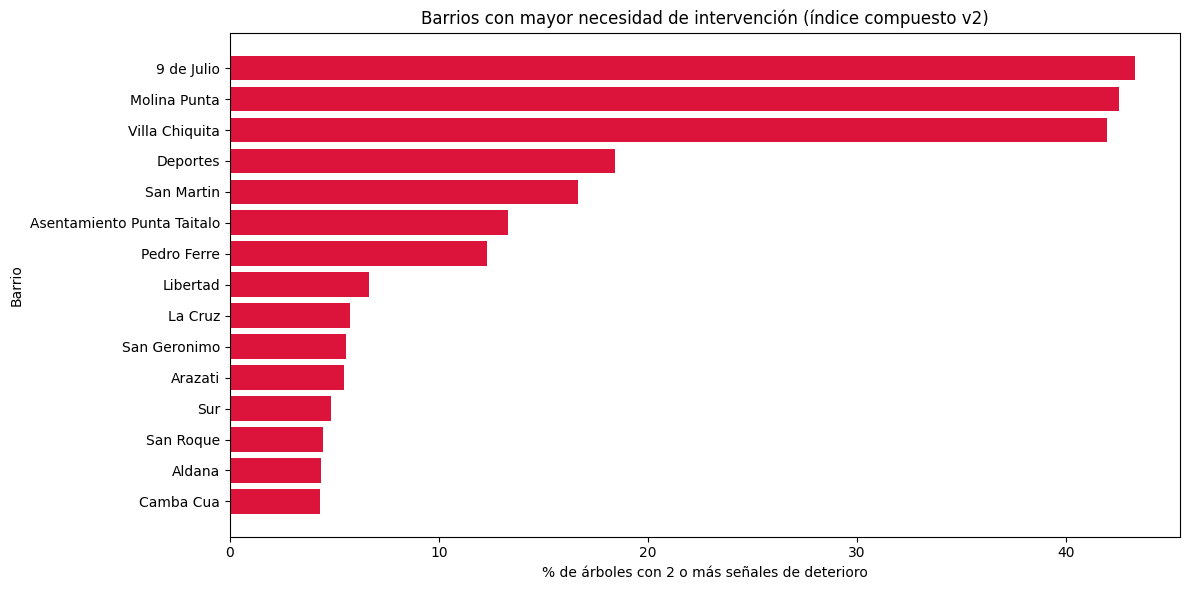

In [ ]:
top15_intervencion = resumen_barrio_final.head(15)

plt.figure(figsize=(12,6))
plt.barh(
    top15_intervencion.index[::-1],
    top15_intervencion["pct_intervencion_v2"][::-1],
    color="crimson"
)

plt.title("Barrios con mayor necesidad de intervención (índice compuesto v2)")
plt.xlabel("% de árboles con 2 o más señales de deterioro")
plt.ylabel("Barrio")
plt.tight_layout()
plt.show()


El índice de intervención v2 combina cinco señales de deterioro del último seguimiento
de cada árbol (riesgo alto, estado sanitario crítico, ahuecamiento severo, inclinación
pronunciada y fase vital añosa/decrépita) y define que un árbol "requiere intervención"
cuando presenta **2 o más** de esas señales a la vez. El indicador por barrio es el
porcentaje de árboles en esa condición, filtrando barrios con menos de 30 árboles para
que el porcentaje no quede inflado por pocos casos. A diferencia del índice v1 (que
dependía casi exclusivamente de los 78 casos de "riesgo de caída alto" en toda la
ciudad), este índice usa variables con mucho más volumen de datos y que están
estadísticamente asociadas entre sí, por lo que da una señal más estable para priorizar
barrios.

## Indicadores de gestión por barrio

La devolución pide convertir conteos en indicadores de gestión. Se arma acá una tabla
única por barrio con los indicadores que la cátedra detalló, todos calculados sobre el
último seguimiento de cada árbol (`df_estado_actual`) salvo donde se indica lo contrario.

In [ ]:
# --- 1) Árboles por hectárea: incluir TODOS los barrios del mapa ---
# Para equidad territorial usamos el padrón completo de árboles, no solo los que
# tienen seguimiento. La base son los polígonos oficiales de barrios.
superficies = (
    gdf_barrios_m[["id_barrios", "nombre_barrio", "sup_geometria_ha"]]
    .drop_duplicates(subset=["id_barrios"])
    .set_index("nombre_barrio")
)

conteo_arboles = (
    arboles_barrios.groupby("nombre_barrio")["id_arbol"].nunique()
)

indicadores_barrio = superficies.copy()
indicadores_barrio["total_arboles"] = (
    conteo_arboles.reindex(indicadores_barrio.index).fillna(0).astype(int)
)
indicadores_barrio["arboles_por_ha"] = (
    indicadores_barrio["total_arboles"] / indicadores_barrio["sup_geometria_ha"]
).round(2)

# Control: los árboles sin barrio asignado no deben desaparecer silenciosamente.
sin_barrio = arboles_barrios["nombre_barrio"].isna().sum()
print(f"Barrios incluidos: {len(indicadores_barrio)}")
print(f"Árboles del padrón sin barrio asignado: {sin_barrio}")
print(f"Total de árboles contabilizados en barrios: {indicadores_barrio['total_arboles'].sum():,}")

indicadores_barrio.sort_values("arboles_por_ha", ascending=False).head(10)


,total_arboles,sup_geometria_ha,arboles_por_ha
nombre_barrio,,,
Pedro Ferre,138,5.707055,24.18
Camba Cua,2545,111.725213,22.78
La Cruz,872,46.698731,18.67
Arazati,765,57.910429,13.21
Centro,990,77.552134,12.77
Aldana,644,58.131723,11.08
Deportes,537,49.425757,10.86
La Rosada,697,77.283195,9.02
Pio X,78,25.560220,3.05


In [ ]:
# --- 2) Mantenimiento vencido por barrio ---
# prox_fecha_mante < hoy, sobre el último seguimiento de cada árbol
hoy = pd.Timestamp.today().normalize()

df_estado_actual["prox_fecha_mante"] = pd.to_datetime(
    df_estado_actual["prox_fecha_mante"], errors="coerce"
)
df_estado_actual["mantenimiento_vencido"] = df_estado_actual["prox_fecha_mante"] < hoy

vencidos_barrio = (
    df_estado_actual[df_estado_actual["mantenimiento_vencido"]]
    .groupby("nombre_barrio")["id_arbol"]
    .nunique()
)
indicadores_barrio["mantenimiento_vencido"] = vencidos_barrio.reindex(indicadores_barrio.index).fillna(0).astype(int)
indicadores_barrio["pct_mantenimiento_vencido"] = (
    indicadores_barrio["mantenimiento_vencido"] / indicadores_barrio["total_arboles"] * 100
).round(2)

print(f"Total de mantenimientos programados vencidos (todo el padrón): "
      f"{df_estado_actual['mantenimiento_vencido'].sum():,}")
indicadores_barrio.sort_values("pct_mantenimiento_vencido", ascending=False).head(10)


Total de mantenimientos programados vencidos (todo el padrón): 3,423


,total_arboles,sup_geometria_ha,arboles_por_ha,mantenimiento_vencido,pct_mantenimiento_vencido
nombre_barrio,,,,,
Galvan,41,57.354481,0.71,37,90.24
Libertad,241,112.232079,2.15,189,78.42
Santa Catalina,243,133.513661,1.82,180,74.07
17 de Agosto,69,155.972096,0.44,46,66.67
Arazati,765,57.910429,13.21,429,56.08
Centro,990,77.552134,12.77,525,53.03
Ciudad de Valencia,31,70.569420,0.44,16,51.61
Santa Maria,33,22.125726,1.49,16,48.48
Molina Punta,40,50.778517,0.79,19,47.50


In [ ]:
# --- 3) Conflicto con vereda y 4) Árboles parasitados por barrio ---
# (mucho mayor volumen que los 78 casos de riesgo alto: dan señal más confiable por barrio)
conflicto_barrio = (
    df_estado_actual[df_estado_actual["levantamiento_vereda"].isin(["Considerable", "Leve"])]
    .groupby("nombre_barrio")["id_arbol"]
    .nunique()
)
parasitados_barrio = (
    df_estado_actual[df_estado_actual["riesgo"].str.contains("Arbol parasitado", na=False)]
    .groupby("nombre_barrio")["id_arbol"]
    .nunique()
)

indicadores_barrio["conflicto_vereda"] = conflicto_barrio.reindex(indicadores_barrio.index).fillna(0).astype(int)
indicadores_barrio["pct_conflicto_vereda"] = (
    indicadores_barrio["conflicto_vereda"] / indicadores_barrio["total_arboles"] * 100
).round(2)

indicadores_barrio["parasitados"] = parasitados_barrio.reindex(indicadores_barrio.index).fillna(0).astype(int)
indicadores_barrio["pct_parasitados"] = (
    indicadores_barrio["parasitados"] / indicadores_barrio["total_arboles"] * 100
).round(2)

indicadores_barrio[["pct_conflicto_vereda", "pct_parasitados"]].sort_values(
    "pct_conflicto_vereda", ascending=False
).head(10)


,pct_conflicto_vereda,pct_parasitados
nombre_barrio,,
9 de Julio,70.19,57.69
San Roque,59.70,7.46
Villa Chiquita,58.06,45.16
Molina Punta,47.50,45.00
San Geronimo,44.44,8.33
Pio X,39.74,11.54
San Martin,38.10,23.81
Sur,37.10,11.29
Malvinas Argentinas,35.85,5.66


In [ ]:
# --- 5) Antigüedad del relevamiento por barrio ---
# hoy - fecha del seguimiento más reciente registrado en cada barrio (usa todos los
# seguimientos, no solo el último por árbol, porque interesa la fecha más reciente que
# existe para ese barrio, la haya hecho el árbol que la haya hecho)
ultima_inspeccion_barrio = df.groupby("nombre_barrio")["fecha_hora"].max()
antiguedad_dias = (hoy - ultima_inspeccion_barrio).dt.days

indicadores_barrio["ultima_inspeccion"] = ultima_inspeccion_barrio.reindex(indicadores_barrio.index)
indicadores_barrio["antiguedad_dias"] = antiguedad_dias.reindex(indicadores_barrio.index)

print("Última inspección registrada en todo el padrón:", df["fecha_hora"].max().date())
indicadores_barrio.sort_values("antiguedad_dias", ascending=False)[
    ["ultima_inspeccion", "antiguedad_dias"]
].head(10)


Última inspección registrada en todo el padrón: 2025-11-15


,ultima_inspeccion,antiguedad_dias
nombre_barrio,,
Pirayui Nuevo,2024-08-14 17:33:13,806
Santa Maria,2024-09-11 15:43:24,778
Santa Catalina,2024-09-18 10:09:54,771
Asentamiento Punta Taitalo,2024-09-20 11:22:25,769
Galvan,2024-09-23 15:03:15,766
Pedro Ferre,2024-09-27 14:30:35,762
San Benito,2024-09-30 14:46:00,759
Union,2024-10-02 14:12:44,757
San Roque,2024-10-10 15:31:48,749


In [ ]:
# --- 6) Diversidad de especies por barrio (índice de Shannon) ---
# H = - sum(p_i * ln(p_i)), p_i = proporción de la especie i dentro del barrio.
# H más bajo = barrio más monoespecífico = más vulnerable a una plaga que ataque esa especie.
import numpy as np

def shannon(especies):
    conteo = especies.value_counts()
    p = conteo / conteo.sum()
    return float(-(p * np.log(p)).sum())

diversidad_barrio = (
    arboles_barrios.groupby("nombre_barrio")["especie"]
    .apply(shannon)
    .rename("shannon_especies")
)
especie_dominante_pct = (
    arboles_barrios.groupby("nombre_barrio")["especie"]
    .apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100)
    .rename("pct_especie_dominante")
)

indicadores_barrio["shannon_especies"] = diversidad_barrio.reindex(indicadores_barrio.index).round(2)
indicadores_barrio["pct_especie_dominante"] = especie_dominante_pct.reindex(indicadores_barrio.index).round(1)

print("A nivel ciudad — especie más común:",
      arboles["especie"].value_counts(normalize=True).round(3).head(1))
indicadores_barrio.sort_values("shannon_especies").head(10)  # barrios menos diversos primero


A nivel ciudad — especie más común: especie
Fresno    0.136
Name: proportion, dtype: float64


,total_arboles,sup_geometria_ha,arboles_por_ha,mantenimiento_vencido,pct_mantenimiento_vencido,conflicto_vereda,pct_conflicto_vereda,parasitados,pct_parasitados,ultima_inspeccion,antiguedad_dias,shannon_especies,pct_especie_dominante
nombre_barrio,,,,,,,,,,,,,
Arazati,765,57.910429,13.21,429,56.08,128,16.73,75,9.80,2024-11-27 15:37:37,701,1.56,42.1
Pirayui Nuevo,51,28.082065,1.82,2,3.92,8,15.69,2,3.92,2024-08-14 17:33:13,806,1.64,45.1
Ntra Sra de la Asuncion,46,73.173221,0.63,5,10.87,3,6.52,0,0.00,2025-09-11 15:40:31,413,1.96,28.3
Asentamiento Punta Taitalo,30,39.674307,0.76,0,0.00,1,3.33,0,0.00,2024-09-20 11:22:25,769,1.96,33.3
Union,32,29.488137,1.09,10,31.25,7,21.88,1,3.12,2024-10-02 14:12:44,757,1.97,34.4
Pio X,78,25.560220,3.05,28,35.90,31,39.74,9,11.54,2025-05-19 15:07:31,528,2.01,32.1
Sargento Cabral,68,25.215157,2.70,20,29.41,9,13.24,4,5.88,2024-11-15 11:57:26,713,2.07,32.4
Molina Punta,40,50.778517,0.79,19,47.50,19,47.50,18,45.00,2024-10-22 15:40:11,737,2.10,25.0
Ciudad de Valencia,31,70.569420,0.44,16,51.61,7,22.58,1,3.23,2025-02-18 17:45:18,618,2.15,29.0


In [ ]:
# --- Tabla de indicadores de gestión: conservar el universo >=30 para comparar con el análisis de intervención ---
# Esta tabla operativa se mantiene separada de la tabla de equidad/prioridad,
# que incluye TODOS los barrios en las celdas siguientes.
indicadores_gestion = indicadores_barrio.reindex(resumen_barrio_final.index).copy()
indicadores_gestion["pct_intervencion_v2"] = resumen_barrio_final["pct_intervencion_v2"]

columnas_finales = [
    "total_arboles", "sup_geometria_ha", "arboles_por_ha",
    "pct_intervencion_v2",
    "pct_mantenimiento_vencido",
    "pct_conflicto_vereda",
    "pct_parasitados",
    "antiguedad_dias",
    "shannon_especies", "pct_especie_dominante",
]

# Incorporar indicadores de gestión calculados previamente, reindexados al universo >=30.
for col in ["pct_mantenimiento_vencido", "pct_conflicto_vereda",
            "pct_parasitados", "antiguedad_dias",
            "shannon_especies", "pct_especie_dominante"]:
    if col in indicadores_barrio.columns:
        indicadores_gestion[col] = indicadores_barrio[col]

indicadores_barrio_final = indicadores_gestion[columnas_finales].sort_values(
    "pct_intervencion_v2", ascending=False
)

indicadores_barrio_final.head(20)


,total_arboles,sup_geometria_ha,arboles_por_ha,pct_intervencion_v2,pct_mantenimiento_vencido,pct_conflicto_vereda,pct_parasitados,antiguedad_dias,shannon_especies,pct_especie_dominante
nombre_barrio,,,,,,,,,,
9 de Julio,104,112.945996,0.92,43.27,25.96,70.19,57.69,706,2.67,19.2
Molina Punta,40,50.778517,0.79,42.50,47.50,47.50,45.00,737,2.10,25.0
Villa Chiquita,31,68.667075,0.45,41.94,29.03,58.06,45.16,526,2.46,19.4
Deportes,537,49.425757,10.86,18.44,34.82,33.89,24.21,711,2.97,23.6
San Martin,42,69.163410,0.61,16.67,21.43,38.10,23.81,528,2.53,19.0
Asentamiento Punta Taitalo,30,39.674307,0.76,13.33,0.00,3.33,0.00,769,1.96,33.3
Pedro Ferre,138,5.707055,24.18,12.32,35.51,32.61,34.78,762,2.37,32.6
Libertad,241,112.232079,2.15,6.64,78.42,14.94,13.69,348,2.72,18.3
La Cruz,872,46.698731,18.67,5.73,31.42,32.22,20.99,723,3.02,15.0


**Cómo leer la tabla:** cada fila es un barrio (con 30 o más árboles). `pct_intervencion_v2`
es el indicador principal de prioridad (índice compuesto de la sección anterior). El resto
son los indicadores operativos que pidió la cátedra: densidad (`arboles_por_ha`), estado del
mantenimiento programado, magnitud real de los problemas de vereda y plagas (mucho más
grandes que el "riesgo de caída alto"), qué tan vieja es la información que se tiene de ese
barrio, y qué tan diversa es su forestación. Un barrio puede tener `pct_intervencion_v2` bajo
simplemente porque hace mucho que no se lo inspecciona — por eso `antiguedad_dias` se lee
junto con el resto y no de manera aislada.

## Indicadores de equidad territorial y prioridad de plantación

Se incorporan dos indicadores complementarios. **La unidad de análisis es el barrio** y el conteo de árboles se toma del padrón completo (`arboles_barrios`, identificadores únicos), no solamente de los árboles que tienen un seguimiento.

| Indicador | Cálculo | Interpretación |
|---|---|---|
| **Árboles cada 1.000 habitantes** | árboles registrados del barrio / población estimada del barrio × 1.000 | Permite comparar la disponibilidad relativa de arbolado respecto de la población residente. |
| **Prioridad de plantación** | Baja densidad de árboles por ha + alta densidad de población por ha | Identifica barrios donde coinciden menor cobertura arbórea registrada y mayor concentración de habitantes. |

**Población:** Censo 2010 por radio censal. La población se distribuye entre barrios en proporción al área de intersección entre cada radio y cada polígono barrial (EPSG:32721). Es una estimación areal: supone que la población se distribuye uniformemente dentro de cada radio.

**Precauciones:** el indicador por habitante combina un inventario de árboles con población del Censo 2010; no representa la población actual. La asignación por superficie tampoco equivale a conocer la ubicación exacta de las viviendas. Por eso debe interpretarse como aproximación territorial, no como medición exacta de acceso individual al arbolado.

No se elimina automáticamente a los barrios de población pequeña: se informa el cociente siempre que la población estimada sea positiva y se agrega una advertencia cuando la base poblacional es menor a 500 habitantes, porque el indicador puede ser inestable.


In [ ]:
# --- Población por barrio (Censo 2010), a partir de los radios censales ---
import glob
import numpy as np

CARPETA_DATOS = "/content/drive/MyDrive/Prác.Prof.2-Estrada2026/Densidad_Poblacional.csv"
MIN_POBLACION_ALERTA = 500  # umbral de advertencia, NO de exclusión del indicador

rutas_radios = glob.glob(CARPETA_DATOS)
if not rutas_radios:
    raise FileNotFoundError(
        "No se encontró el CSV «Densidad poblacional» en " + CARPETA_DATOS +
        ". Archivos disponibles: " + str(os.listdir(os.path.dirname(CARPETA_DATOS)))
    )
radios_csv = pd.read_csv(rutas_radios[0])
print(f"Archivo: {os.path.basename(rutas_radios[0])}")
print(f"Radios censales: {fmt_num(len(radios_csv))} | población total: {fmt_num(radios_csv['total_poblacion'].sum())}")
print(f"Nulos en total_poblacion: {radios_csv['total_poblacion'].isna().sum()} | gid duplicados: {radios_csv['gid'].duplicated().sum()}")

# Geometrías de radios en WGS84; reparar las inválidas antes de intersectar.
radios = gpd.GeoDataFrame(
    radios_csv.drop(columns="the_geom"),
    geometry=radios_csv["the_geom"].map(lambda s: shape(json.loads(s))),
    crs="EPSG:4326",
)
invalidos = ~radios.geometry.is_valid
if invalidos.any():
    radios.loc[invalidos, "geometry"] = radios.loc[invalidos, "geometry"].buffer(0)
print(f"Geometrías de radios inválidas reparadas: {int(invalidos.sum())}")

radios_m = radios.to_crs("EPSG:32721")
radios_m["area_radio_ha"] = radios_m.geometry.area / 10_000

# Control de consistencia de unidades de la fuente censal.
razon_area = radios_m["area_radio_ha"] / radios_m["superficie"]
print(f"Control de superficie (área geométrica / columna 'superficie'): "
      f"{fmt_num(razon_area.min(), 3)} a {fmt_num(razon_area.max(), 3)}")
dens_calculada = radios_m["total_poblacion"] / radios_m["superficie"]
print(f"Correlación densidad publicada vs. población/superficie: "
      f"{fmt_num(dens_calculada.corr(radios_m['densidad_poblacion']), 3)}")

# Usar el mismo conjunto completo de polígonos de barrios de la sección anterior.
barrios_m = gdf_barrios_m[["id_barrios", "nombre_barrio", "geometry"]].copy()
geom_barrios = barrios_m.geometry
union_barrios = geom_barrios.union_all() if hasattr(geom_barrios, "union_all") else geom_barrios.unary_union
print(f"Superficie de barrios superpuesta entre sí: "
      f"{fmt_num((geom_barrios.area.sum() - union_barrios.area) / 10_000, 2)} ha")

# Intersección radio × barrio: asignación proporcional a la fracción de superficie.
inter = gpd.overlay(
    radios_m[["gid", "total_poblacion", "area_radio_ha", "geometry"]],
    barrios_m, how="intersection", keep_geom_type=True
)
inter["fraccion_del_radio"] = inter.geometry.area / 10_000 / inter["area_radio_ha"]
inter["poblacion_asignada"] = inter["total_poblacion"] * inter["fraccion_del_radio"]

fraccion_por_radio = inter.groupby("gid")["fraccion_del_radio"].sum()
print(f"Fracción máxima de un radio asignada a barrios: {fmt_num(fraccion_por_radio.max(), 3)} (no debería superar 1)")
asignada = inter["poblacion_asignada"].sum()
total_censo = radios_m["total_poblacion"].sum()
print(f"Población asignada a algún barrio: {fmt_num(asignada)} de {fmt_num(total_censo)} "
      f"({fmt_pct(asignada / total_censo * 100)}). El resto cae fuera de los polígonos de barrio.")

poblacion_barrio = inter.groupby("nombre_barrio")["poblacion_asignada"].sum()
indicadores_barrio["poblacion_estimada_censo2010"] = poblacion_barrio.reindex(
    indicadores_barrio.index
)
indicadores_barrio["poblacion_por_ha"] = (
    indicadores_barrio["poblacion_estimada_censo2010"] /
    indicadores_barrio["sup_geometria_ha"]
).where(indicadores_barrio["poblacion_estimada_censo2010"] > 0).round(2)

# No ocultar barrios pequeños: calcular cuando el denominador es positivo y advertir
# cuando la población estimada es baja. Población nula/no asignada => indicador nulo.
indicadores_barrio["arboles_por_1000_habitantes"] = (
    indicadores_barrio["total_arboles"] /
    indicadores_barrio["poblacion_estimada_censo2010"] * 1000
).where(indicadores_barrio["poblacion_estimada_censo2010"] > 0).round(2)

indicadores_barrio["base_poblacional_baja"] = (
    indicadores_barrio["poblacion_estimada_censo2010"] < MIN_POBLACION_ALERTA
)
poblacion_disponible = indicadores_barrio["poblacion_estimada_censo2010"].notna().any()

sin_poblacion = int((indicadores_barrio["poblacion_estimada_censo2010"].isna() |
                     (indicadores_barrio["poblacion_estimada_censo2010"] <= 0)).sum())
base_baja = int(indicadores_barrio["base_poblacional_baja"].sum())
print(f"Barrios sin población positiva asignada: {sin_poblacion}")
print(f"Barrios con menos de {MIN_POBLACION_ALERTA} habitantes estimados (indicador calculado, interpretar con cautela): {base_baja}")
print("Recordatorio: población del Censo 2010, distribuida proporcionalmente por superficie.")

(indicadores_barrio[["total_arboles", "poblacion_estimada_censo2010",
                     "arboles_por_1000_habitantes", "base_poblacional_baja"]]
 .sort_values("arboles_por_1000_habitantes").head(20))


Archivo: Densidad_Poblacional.csv
Radios censales: 319 | población total: 354.005
Nulos en total_poblacion: 0 | gid duplicados: 0
Geometrías de radios inválidas reparadas: 0
Control de superficie (área geométrica / columna 'superficie'): 0,999 a 1,001  -> 'superficie' está en hectáreas
Control de densidad (correlación de 'densidad_poblacion' con población/superficie): 1,000  -> 'densidad_poblacion' es hab/ha
Superficie de barrios superpuesta entre sí: 0,07 ha
Fracción máxima de un radio asignada a barrios: 1,000 (no debería superar 1)
Población asignada a algún barrio: 335.817 de 354.005 (94,9%). El resto cae fuera de los polígonos de barrio.
Barrios sin árboles/1.000 hab. por población menor a 500: 3 de 32
Referencia (barrios con 30 o más árboles y población suficiente): 59,7 árboles cada 1.000 habitantes
Recordatorio: población del Censo 2010, repartida proporcionalmente por superficie.


,total_arboles,poblacion_estimada_censo2010,arboles_por_1000_habitantes
nombre_barrio,,,
Villa Chiquita,31,5667.0,5.47
San Geronimo,36,5739.0,6.27
San Martin,42,6300.0,6.67
17 de Agosto,69,10124.0,6.82
9 de Julio,104,12878.0,8.08
Union,32,3592.0,8.91
Galvan,41,4456.0,9.20
Ntra Sra de la Asuncion,46,4972.0,9.25
Malvinas Argentinas,53,5685.0,9.32


### Prioridad de plantación

La prioridad se calcula para **todos los barrios del mapa**, incluso aquellos con pocos árboles o sin árboles registrados. La regla principal es:

- **Baja densidad arbórea:** árboles registrados por hectárea por debajo de la mediana de los barrios.
- **Alta densidad poblacional:** habitantes estimados por hectárea por encima de la mediana.

Un barrio que cumple simultáneamente ambas condiciones queda clasificado como prioritario. Así se evita que el filtro de “30 o más árboles” excluya justamente a barrios que podrían necesitar nuevas plantaciones.

Para ordenar los barrios prioritarios se calcula un índice descriptivo de 0 a 1: promedio entre el percentil inverso de árboles/ha (menos árboles = mayor prioridad) y el percentil directo de habitantes/ha (más habitantes = mayor prioridad). El índice ordena; **la clasificación prioritaria la determina el cruce de medianas**, no un corte arbitrario del índice.

El porcentaje de árboles en estado crítico se presenta como contexto para distinguir dos situaciones: plantar donde hay déficit de arbolado y el arbolado existente está relativamente sano, o combinar la plantación con intervenciones sobre el arbolado deteriorado. No se incorpora al índice de prioridad de plantación porque mide una necesidad de mantenimiento/intervención distinta.

La prioridad es una orientación territorial preliminar. Antes de definir sitios y cantidades de plantación deben verificarse veredas, servicios subterráneos/aéreos, espacio disponible, especies apropiadas y condiciones ambientales.


Medianas de referencia: 1,40 árboles/ha | 75,9 habitantes/ha | 0,0% en estado crítico
Barrios priorizados: 9 de 32


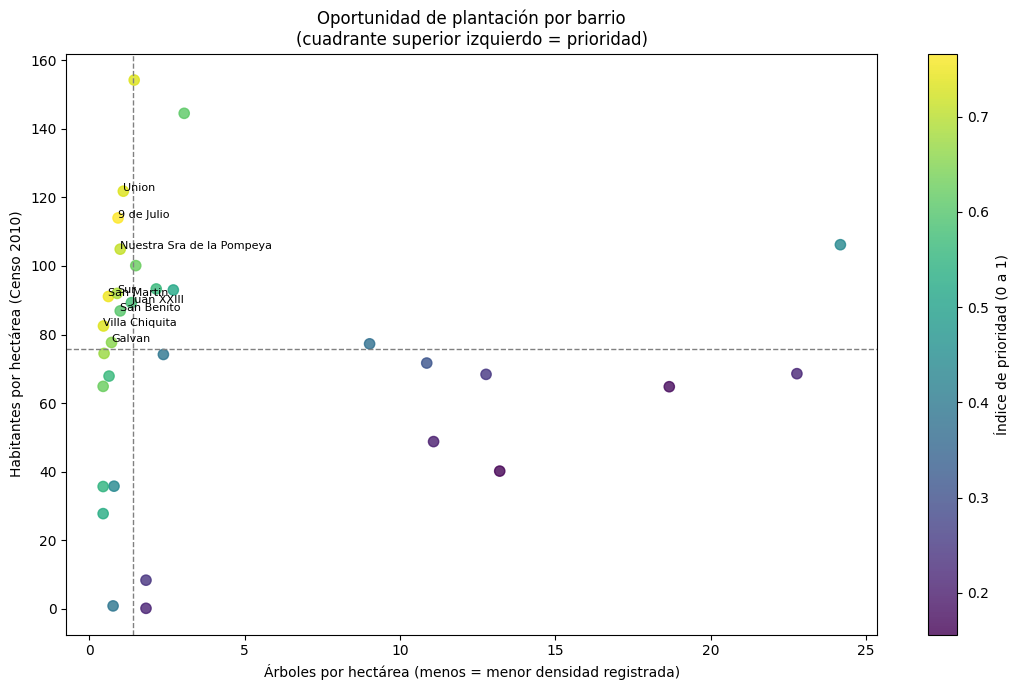

,total_arboles,sup_geometria_ha,arboles_por_ha,poblacion_estimada_censo2010,poblacion_por_ha,arboles_por_1000_habitantes,pct_estado_critico,indice_prioridad_plantacion,prioridad_plantacion,lectura
nombre_barrio,,,,,,,,,,
9 de Julio,104,112.945996,0.92,12878.0,114.0,8.08,0.96,0.766,True,"Intervenir y plantar: poco arbolado, mucha pob..."
San Martin,42,69.163410,0.61,6300.0,91.1,6.67,4.76,0.750,True,"Intervenir y plantar: poco arbolado, mucha pob..."
Villa Chiquita,31,68.667075,0.45,5667.0,82.5,5.47,3.23,0.734,True,"Intervenir y plantar: poco arbolado, mucha pob..."
Union,32,29.488137,1.09,3592.0,121.8,8.91,0.00,0.734,True,"Intervenir y plantar: poco arbolado, mucha pob..."
Nuestra Sra de la Pompeya,37,37.357594,0.99,3918.0,104.9,9.44,0.00,0.711,True,"Intervenir y plantar: poco arbolado, mucha pob..."
Sur,62,69.277080,0.89,6375.0,92.0,9.73,0.00,0.688,True,"Intervenir y plantar: poco arbolado, mucha pob..."
Galvan,41,57.354481,0.71,4456.0,77.7,9.20,0.00,0.656,True,"Intervenir y plantar: poco arbolado, mucha pob..."
San Benito,52,52.733889,0.99,4580.0,86.9,11.35,0.00,0.602,True,"Intervenir y plantar: poco arbolado, mucha pob..."
Juan XXIII,105,77.585762,1.35,6927.0,89.3,15.16,0.95,0.578,True,"Intervenir y plantar: poco arbolado, mucha pob..."


In [ ]:
# --- Prioridad de plantación: todos los barrios, incluidos los de cero/pocos árboles ---
import numpy as np

prioridad = indicadores_barrio.dropna(
    subset=["arboles_por_ha", "poblacion_por_ha"]
).copy()

# Estado crítico: porcentaje de árboles con último seguimiento clasificado como Malo/Muerto.
# Se calcula aparte; no altera la prioridad de plantación.
estado_critico_barrio = (
    df_estado_actual.groupby("nombre_barrio")["senal_estado_critico"].mean() * 100
)
prioridad["pct_estado_critico"] = estado_critico_barrio.reindex(prioridad.index).round(2)

mediana_arboles = prioridad["arboles_por_ha"].median()
mediana_poblacion = prioridad["poblacion_por_ha"].median()

# Índice relativo continuo: 0-1, solo para ordenar los barrios.
percentil_bajo_arbolado = 1 - prioridad["arboles_por_ha"].rank(
    method="average", pct=True
)
percentil_alta_poblacion = prioridad["poblacion_por_ha"].rank(
    method="average", pct=True
)
prioridad["indice_prioridad_plantacion"] = (
    0.5 * percentil_bajo_arbolado + 0.5 * percentil_alta_poblacion
).round(3)

# Regla transparente: deben cumplirse simultáneamente las dos condiciones.
prioridad["prioridad_plantacion"] = (
    (prioridad["arboles_por_ha"] < mediana_arboles) &
    (prioridad["poblacion_por_ha"] > mediana_poblacion)
)

mediana_critico = prioridad["pct_estado_critico"].median()
prioridad["lectura"] = np.select(
    [
        prioridad["prioridad_plantacion"] &
        (prioridad["pct_estado_critico"] < mediana_critico),
        prioridad["prioridad_plantacion"] &
        (prioridad["pct_estado_critico"] >= mediana_critico),
        prioridad["prioridad_plantacion"] &
        prioridad["pct_estado_critico"].isna(),
    ],
    [
        "Priorizar plantación; deterioro observado relativamente bajo",
        "Combinar plantación con intervención del arbolado existente",
        "Priorizar evaluación: no hay datos suficientes de estado",
    ],
    default="No prioritario según el cruce de medianas",
)

columnas_prioridad = [
    "total_arboles", "sup_geometria_ha", "arboles_por_ha",
    "poblacion_estimada_censo2010", "poblacion_por_ha",
    "arboles_por_1000_habitantes", "base_poblacional_baja",
    "pct_estado_critico", "indice_prioridad_plantacion",
    "prioridad_plantacion", "lectura"
]
ranking_plantacion = prioridad[columnas_prioridad].sort_values(
    ["prioridad_plantacion", "indice_prioridad_plantacion"],
    ascending=[False, False]
)

print(f"Barrios evaluables (con población positiva): {len(prioridad)}")
print(f"Medianas: {fmt_num(mediana_arboles, 2)} árboles/ha | "
      f"{fmt_num(mediana_poblacion, 2)} habitantes/ha")
print(f"Barrios prioritarios: {int(prioridad['prioridad_plantacion'].sum())} de {len(prioridad)}")

plt.figure(figsize=(12, 7))
sc = plt.scatter(
    prioridad["arboles_por_ha"], prioridad["poblacion_por_ha"],
    c=prioridad["indice_prioridad_plantacion"], s=55, alpha=0.8
)
plt.colorbar(sc, label="Índice relativo de prioridad (0 a 1)")
plt.axvline(mediana_arboles, linestyle="--", linewidth=1, color="gray")
plt.axhline(mediana_poblacion, linestyle="--", linewidth=1, color="gray")
for nombre, fila in prioridad[prioridad["prioridad_plantacion"]].iterrows():
    plt.annotate(str(nombre), (fila["arboles_por_ha"], fila["poblacion_por_ha"]), fontsize=8)
plt.xlabel("Árboles registrados por hectárea")
plt.ylabel("Habitantes estimados por hectárea (Censo 2010)")
plt.title("Prioridad territorial de plantación por barrio\n(arriba a la izquierda: baja densidad arbórea y alta densidad poblacional)")
plt.tight_layout()
plt.show()

ranking_plantacion[ranking_plantacion["prioridad_plantacion"]]


**Cómo leer la tabla:** se incluyen todos los barrios con población estimada positiva, sin exigir un mínimo de árboles registrados. `arboles_por_1000_habitantes` es un indicador descriptivo calculado con población del Censo 2010; cuando la base es menor a 500 habitantes se marca `base_poblacional_baja=True` para advertir que el cociente puede variar mucho. `prioridad_plantacion=True` identifica los barrios que combinan densidad arbórea inferior a la mediana y densidad poblacional superior a la mediana. El índice continuo sirve para ordenar dentro de esa lectura; el porcentaje de estado crítico es contextual y no suma puntos al índice.


# Análisis de Correspondencias Múltiples (MCA)

El índice de intervención v2 combina cinco variables categóricas (`riesgo`, `estado_salud`,
`ahuecamiento`, `inclinacion`, `fase_vital`) sumando señales binarias, con el mismo peso
para cada una. Esa es una decisión razonable pero arbitraria: ¿realmente esas cinco
variables se mueven juntas en los datos, o el índice está mezclando cosas que no tienen
relación?

El MCA responde esa pregunta de forma visual: proyecta todas las categorías de esas
variables en un plano de forma que categorías que tienden a **aparecer juntas en el mismo
árbol** queden cerca entre sí, y categorías que casi nunca coinciden queden lejos. Si las
categorías "malas" de las cinco variables (riesgo alto, estado muerto, ahuecamiento
severo, etc.) terminan agrupadas en una misma zona del plano, eso es evidencia de que
existe un verdadero "síndrome de deterioro" compartido — y de que sumarlas en un único
índice tiene sentido estadístico, no solo de negocio.

In [ ]:
!pip install prince

In [ ]:
# Seleccionamos las variables categóricas para el MCA.
# Se toman de 'df_estado_actual' (una fila por árbol = su último seguimiento), y se
# excluyen los árboles sin ningún seguimiento (quedarían con NaN en las seis columnas
# y el MCA no admite nulos).
columnas_mca = [
    "riesgo",
    "estado_salud",
    "inclinacion",
    "ahuecamiento",
    "levantamiento_vereda",
    "fase_vital",
]

variables = df_estado_actual[columnas_mca].dropna()

print(f"Árboles incluidos en el MCA: {len(variables):,} de {len(df_estado_actual):,} "
      f"({len(variables) / len(df_estado_actual) * 100:.1f}%)")
variables.dtypes


In [ ]:
# Ajuste del modelo MCA.
# Usamos más de 2 componentes acá (10) para poder calcular correctamente el % de
# varianza que explican las dos primeras dimensiones sobre la inercia TOTAL, no solo
# sobre las dos que se iban a graficar. Para el gráfico solo usamos las dos primeras.
mca = prince.MCA(
    n_components=10,
    random_state=42
)

mca = mca.fit(variables)


In [ ]:
# Coordenadas
coord = mca.column_coordinates(variables)

coord.head()

,0,1
riesgo__Arbol parasitado ( con hongos ),0.817556,1.928288
riesgo__Arbol parasitado (con especies vegetales),1.153164,-0.632613
riesgo__Arbol parasitado (insectos),0.736432,1.885694
riesgo__Arbol parasitado (otros animales),-0.078105,0.201824
riesgo__Con riesgo de caída (alto),2.826068,5.083332


In [ ]:
# Varianza explicada por cada dimensión, sobre la inercia total del modelo
# (con las 10 dimensiones que se ajustaron arriba).
autovalores = mca.eigenvalues_
pct_por_dimension = autovalores / autovalores.sum() * 100
pct_acumulado = pct_por_dimension.cumsum()

varianza_explicada = pd.DataFrame({
    "autovalor": autovalores,
    "% varianza": pct_por_dimension.round(2),
    "% acumulado": pct_acumulado.round(2),
})
varianza_explicada.index = [f"Dim {i+1}" for i in range(len(autovalores))]

print(f"Las dos primeras dimensiones explican el {pct_acumulado[1]:.2f}% de la variabilidad total.")
varianza_explicada.head(5)


**Por qué esto importa:** si las dos primeras dimensiones concentran la mayor parte de
la varianza, el gráfico 2D de más abajo es una representación fiel de las relaciones
entre categorías (no se está perdiendo información relevante al aplastar todo a 2
dimensiones). Si el porcentaje fuera bajo (por ejemplo, menos del 40-50%), habría que
mirar también la dimensión 3 antes de sacar conclusiones del gráfico.

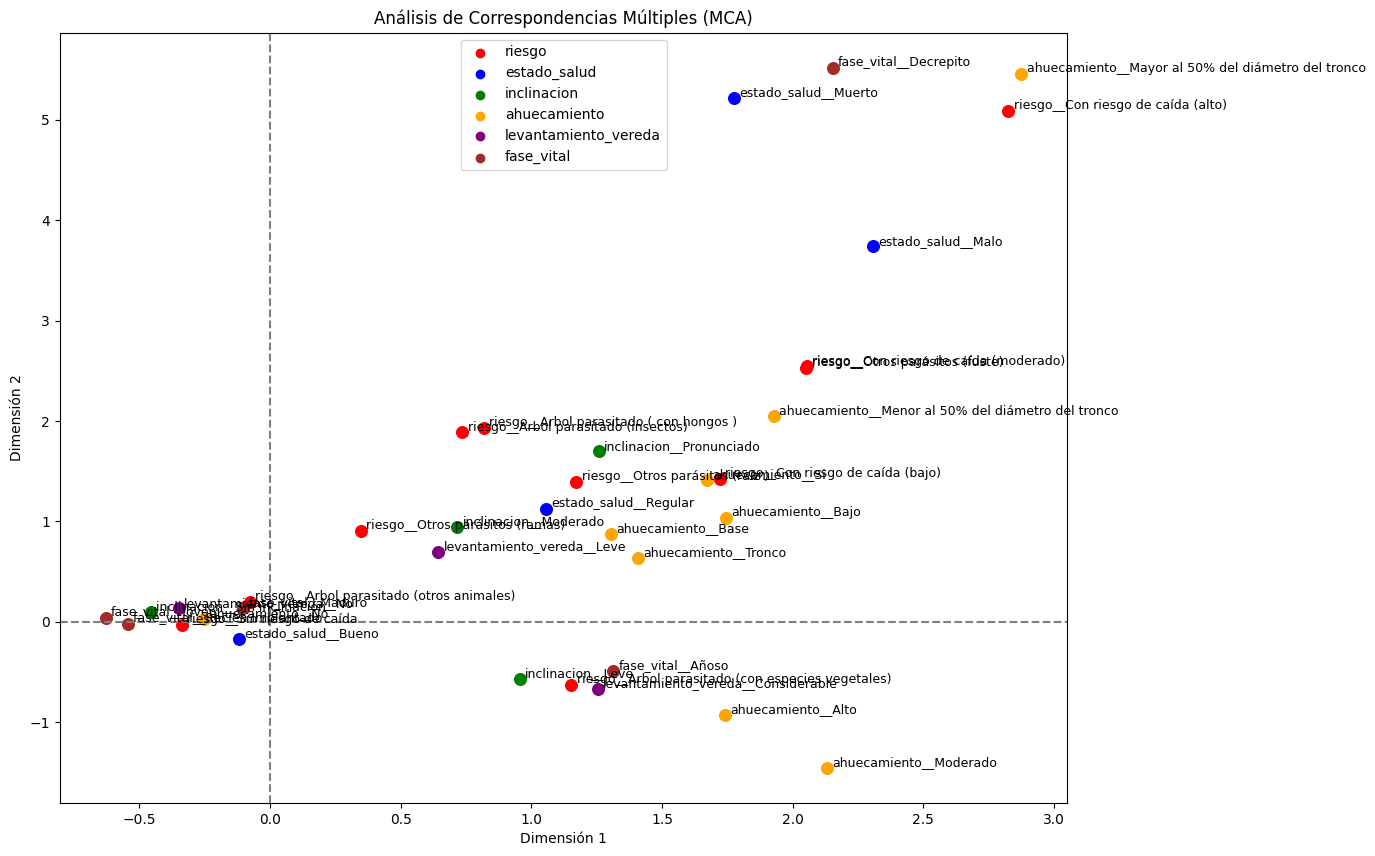

In [ ]:
import matplotlib.pyplot as plt

coord = mca.column_coordinates(variables)

plt.figure(figsize=(13,10))

colores = {
    "riesgo":"red",
    "estado_salud":"blue",
    "inclinacion":"green",
    "ahuecamiento":"orange",
    "levantamiento_vereda":"purple",
    "fase_vital":"brown"
}

for nombre in coord.index:

    variable = nombre.split("__")[0]

    plt.scatter(
        coord.loc[nombre,0],
        coord.loc[nombre,1],
        color=colores[variable],
        s=70
    )

    plt.text(
        coord.loc[nombre,0]+0.02,
        coord.loc[nombre,1]+0.02,
        nombre,
        fontsize=9
    )

plt.axhline(0,color="gray",linestyle="--")
plt.axvline(0,color="gray",linestyle="--")

plt.xlabel("Dimensión 1")
plt.ylabel("Dimensión 2")

plt.title("Análisis de Correspondencias Múltiples (MCA)")

# Leyenda
for variable,color in colores.items():
    plt.scatter([],[],color=color,label=variable)

plt.legend()

plt.show()

El gráfico de arriba muestra las 10 dimensiones ajustadas resumidas en 2 (Dim 1 y Dim 2,
las que más varianza explican — ver el porcentaje impreso arriba). Cada punto es una
categoría (por ejemplo, `riesgo__Con riesgo de caída (alto)`); dos categorías que
aparecen cerca tienden a coincidir en el mismo árbol con más frecuencia de lo esperado
por azar.

In [ ]:
coord["distancia"] = (
    coord[0]**2 +
    coord[1]**2
)**0.5

coord2 = coord.sort_values(
    "distancia",
    ascending=False
).head(20)

In [ ]:
plt.figure(figsize=(12,9))

for nombre in coord2.index:

    variable = nombre.split("__")[0]

    plt.scatter(
        coord2.loc[nombre,0],
        coord2.loc[nombre,1],
        color=colores[variable],
        s=80
    )

    plt.text(
        coord2.loc[nombre,0]+0.03,
        coord2.loc[nombre,1]+0.03,
        nombre,
        fontsize=10
    )

plt.axhline(0,color="gray",ls="--")
plt.axvline(0,color="gray",ls="--")

plt.title("MCA - Categorías con mayor contribución (top 20 más alejadas del origen)")

# Leyenda por variable (con placeholders, igual que en el gráfico general)
for variable, color in colores.items():
    plt.scatter([], [], color=color, label=variable)

plt.legend()

plt.show()

**Cómo leer este segundo gráfico:** en vez de mostrar las ~25 categorías completas,
nos quedamos con las 20 que están más lejos del origen (mayor `distancia` en el código
de arriba) — son las que más diferencian a los árboles entre sí y las que sostienen la
interpretación de las dos dimensiones.

En el cuadrante superior derecho aparece un grupo de categorías claramente próximas
entre sí:

- `riesgo__Con riesgo de caída (alto)`
- `estado_salud__Muerto` / `estado_salud__Malo`
- `fase_vital__Decrepito`
- `ahuecamiento__Mayor al 50% del diámetro del tronco`

Que estas categorías —de cinco variables distintas— caigan juntas es la evidencia que
buscábamos: no es casualidad que el índice de intervención v2 las combine, porque en los
datos **realmente tienden a presentarse en el mismo árbol**. Un árbol muerto o con
ahuecamiento severo casi siempre acumula también riesgo alto y fase vital decrépita; no
son cuatro problemas independientes, son la misma foto vista desde cuatro variables.

En una zona intermedia aparece un segundo grupo:

- `riesgo__Con riesgo de caída (moderado)`
- `estado_salud__Regular`
- `ahuecamiento__Menor al 50% del diámetro del tronco`
- `inclinacion__Pronunciado`

Este grupo describe árboles con deterioro visible pero no crítico: candidatos a
mantenimiento preventivo antes de convertirse en un caso de intervención urgente.

Del lado opuesto del plano (izquierda/abajo, lejos del primer grupo) se agrupan:

- `estado_salud__Bueno`
- categorías de `fase_vital` jóvenes/maduras
- `riesgo__Sin riesgo de caída`

Es el perfil de un árbol sano, sin nada que priorizar.

**Una salvedad de calidad de datos:** `ahuecamiento` tiene categorías inconsistentes en
el CSV original (`"Menor al 50% del diámetro del tronco"` convive con valores sueltos
como `"Bajo"`, `"Alto"`, `"Si"`, `"No"`, `"Tronco"`). Eso reparte la información de una
misma idea entre varias categorías y le resta fuerza a esa variable dentro del MCA; una
recodificación de `ahuecamiento` a una escala más consistente (por ejemplo,
Ninguno/Leve/Severo) probablemente haría este eje todavía más nítido — queda como
mejora pendiente, no se aplicó acá para no alterar los datos originales sin
autorización de la cátedra.

## Conclusión del MCA y para qué sirve en este trabajo

**Conclusión.** El MCA confirma, de forma independiente y puramente exploratoria (no usa
el índice de intervención v2 ni ninguna fórmula que hayamos definido nosotros), que
existe un verdadero **eje de deterioro** en los datos: las categorías "graves" de
`riesgo`, `estado_salud`, `ahuecamiento` y `fase_vital` se agrupan juntas en el plano, y
las categorías "sanas" de esas mismas variables se agrupan del lado opuesto. Ese eje es,
además, la dimensión que más varianza explica del dataset (ver el % impreso arriba), o
sea que no es un patrón menor: es la principal fuente de variabilidad entre árboles.

**Para qué sirve esto en la práctica:**

1. **Justifica la construcción del índice v2.** Antes de este análisis, sumar cinco
   señales binarias era una decisión razonable pero arbitraria. Después del MCA, hay
   evidencia de que esas cinco variables miden en gran medida *la misma cosa* — así que
   combinarlas no es forzar una relación que no existe, es reconocer una que ya estaba
   en los datos.
2. **Señala qué variable es más débil.** `ahuecamiento` aparece con categorías
   fragmentadas por inconsistencias de carga, lo que sugiere que su aporte al índice v2
   es más ruidoso que el de las otras cuatro. Si en una iteración futura se quisiera
   ponderar las señales en vez de sumarlas con el mismo peso, esta es la que más se
   beneficiaría de revisarse primero.
3. **Da una alternativa de score continuo.** La coordenada de cada árbol en la Dimensión
   1 del MCA (no graficada acá, pero calculable con `mca.row_coordinates(variables)`) es,
   en los hechos, un índice de severidad continuo derivado directamente de los datos, sin
   necesidad de fijar un umbral como "2 o más señales". Podría usarse para ordenar
   árboles dentro de un mismo barrio por prioridad, en vez de solo clasificarlos en
   dos grupos.
4. **Es una herramienta de comunicación, no solo de validación técnica.** El gráfico es
   una forma directa de mostrarle a alguien sin formación estadística (un funcionario
   municipal, por ejemplo) que "riesgo alto", "árbol muerto" y "ahuecamiento severo" no
   son tres problemas sueltos: es el mismo fenómeno visto desde tres ángulos, lo cual
   respalda por qué conviene actuar sobre esos árboles de manera integral y no
   ficha por ficha.

In [ ]:
# Resumen de las tres señales con más volumen (reutilizando las columnas ya
# calculadas en la sección del índice de intervención v2, sin redefinirlas de nuevo).
print(f"Árboles con riesgo de caída alto: {df_estado_actual['senal_riesgo_alto'].sum():,}")
print(f"Árboles parasitados: "
      f"{df_estado_actual['riesgo'].str.contains('Arbol parasitado', na=False).sum():,}")
print(f"Árboles con conflicto de vereda: "
      f"{df_estado_actual['levantamiento_vereda'].isin(['Considerable', 'Leve']).sum():,}")


---
# Metodología

### 1. Fuente y fecha
- `arboles.csv` — Aplicación de Arbolado Urbano, Municipalidad de Corrientes. Publicado el 13/03/2024, última actualización: 22/09/2025.
- `Seguimiento_Arboles.csv` — misma fuente. Publicado el 13/03/2024, última actualización: 13/08/2025.
- `barrios_de_la_ciudad.csv` — delimitación de barrios (Responsable:
Dirección General de Sistemas de Información Geográfica ),  fecha de actualización:01/10/2025 publicada en el portal de datos abiertos.
- Los tres archivos se bajaron para este trabajo el día: 07/07/2026.
- `Densidad_Poblacional.csv` — delimitación de barrios (Responsable:
Dirección General de Sistemas de Información Geográfica ), Fecha de Creación: desconocido, fecha de actualización:01/10/2025 publicada en el portal de datos abiertos.

### 2. Qué se transformó (filas antes → después de cada paso)
| Paso | Filas antes | Filas después | Nota |
|---|---|---|---|
| Lectura `arboles.csv` | — | 10.286 | sin nulos |
| Lectura `Seguimiento_Arboles.csv` | — | 12.597 | sin nulos |
| Unificación de `barrios` con `id_barrios` duplicado (Collantes, Molina Punta) | 140 | 138 | no se descarta ninguna fila: se unen (`dissolve`) las dos geometrías de cada barrio repetido, porque son fragmentos de polígono del mismo barrio, no un error de carga |
| Reparación `sup_ha` (separador de miles) | — | — | conversión de string mal formateado a float |
| Cruce espacial árbol → barrio (`sjoin`, `within`) | 10.286 árboles | 9.669 geolocalizados dentro de algún polígono | 617 quedan fuera (acordado con la cátedra) |
| Seguimientos huérfanos (`id_arbol` sin match en `arboles.csv`) | 12.597 | se identifican y **se descartan explícitamente** antes del merge | ver conteo impreso en la sección correspondiente |
| Merge `arboles` × `mantenimiento` (`how="left"`) | 10.286 árboles | fila por cada combinación árbol×seguimiento | usado solo para el análisis exploratorio bivariado |
| Último seguimiento por árbol (`groupby("id_arbol").last()`) | fila por seguimiento | 1 fila por árbol (10.286) | base de `df_estado_actual`, usada para todos los indicadores de gestión |
| Exclusión de "Registro de Árbol" del análisis de mantenimiento | 12.597 | resto tras filtrar el alta de padrón | evita que "dar de alta" se lea como "tipo de mantenimiento más frecuente" |

### 3. Cómo se calcula cada indicador
- **Mantenimiento más frecuente**: moda de `tipo_seguimiento` **excluyendo** "Registro de Árbol".
- **Índice de intervención v2** (por árbol): cantidad de señales presentes entre
  `riesgo == alto`, `estado_salud ∈ {Malo, Muerto}`, `ahuecamiento severo`,
  `inclinacion == Pronunciado`, `fase_vital ∈ {Añoso, Decrepito}`. Un árbol "requiere intervención" si tiene 2 o más señales. El indicador por barrio es el % de árboles en esa condición, sobre barrios con ≥ 30 árboles.
- **Árboles por hectárea**: árboles del barrio (último seguimiento) ÷ `sup_geometria_ha` (superficie calculada desde la geometría de cada barrio, no `sup_ha` del CSV: `sup_ha` tenía el separador de miles roto y 3 valores nulos, mientras que `sup_geometria_ha` se puede calcular para 137 de los 138 barrios, una vez unificadas las geometrías duplicadas de Collantes y Molina Punta).
- **Mantenimiento vencido**: `prox_fecha_mante < hoy`, sobre el último seguimiento de cada árbol.
- **Conflicto con vereda**: `levantamiento_vereda ∈ {Considerable, Leve}`.
- **Árboles parasitados**: `riesgo` empieza con "Arbol parasitado".
- **Antigüedad del relevamiento**: hoy − fecha del seguimiento más reciente registrado en  el barrio (usa todos los seguimientos del barrio, no solo el último por árbol).
- **Diversidad de especies**: índice de Shannon H = −Σ pᵢ·ln(pᵢ), pᵢ = proporción de cada especie dentro del barrio; y % de la especie dominante como lectura complementaria.

### 4. Supuestos
- Se toma el **último seguimiento de cada árbol según `fecha_hora`** como su estado actual; los seguimientos anteriores del mismo árbol no se usan para los indicadores de gestión (sí se usan, sin deduplicar, en el análisis bivariado exploratorio de riesgo × otras variables).
- "Registro de Árbol" **no** se cuenta como mantenimiento; representa el alta del árbol en el padrón, no una intervención.
- Los seguimientos sin `id_arbol` coincidente en `arboles.csv` se descartan, pero se cuantifican antes de descartarlos.
- La exclusión de los 617 árboles fuera de todos los polígonos y de los barrios sin ningún árbol asignado está acordada con la cátedra; se documenta como decisión, no como omisión, y se muestra el indicador de cobertura correspondiente.
- Un árbol "requiere intervención" (índice v2) si presenta 2 o más señales de deterioro simultáneas; este umbral es un criterio metodológico propio del equipo, no un estándar normativo.

### 5. Límites
- El padrón tiene una fecha de corte: la última inspección registrada es del 20/11/2025 y los 3.426 mantenimientos programados están todos vencidos a la fecha de este análisis.
  Los indicadores de estado (riesgo, salud, etc.) reflejan la **última vez que se inspeccionó cada árbol**, no necesariamente su estado real hoy.
- El cruce espacial deja fuera 617 árboles y 33 barrios sin registros; los indicadores por barrio no cubren esos casos.
- `sup_ha` proviene del dataset de barrios tal como se publicó (con su reparación de formato); no se validó contra una medición catastral independiente.
- El índice de intervención v2 es un indicador relativo (ranking), no una escala
  validada externamente: sirve para priorizar, no para fijar umbrales normativos de intervención.

### 6. Reproducibilidad
- Este notebook lee los tres CSV desde Google Drive (`drive.mount`); para reproducirlo hace falta acceso a esa carpeta o reemplazar las rutas de lectura por las propias.
- El tablero (Streamlit) que consume estos datos vive en un repositorio aparte y no se incluye en este notebook; sus correcciones (orden de los rankings, `config.toml`, mapa coroplético) deben aplicarse en el `app.py` de ese repo.
- En el repo, hay  un `README.md` con: cómo correr la app (`streamlit run  app.py`), qué hace cada archivo, y con qué versión de cada CSV se generó el tablero
  (fecha de descarga de cada fuente, ver punto 1).

---
### Nota sobre las advertencias 3 y 4 de la devolución (tablero Streamlit)

Este archivo es el notebook de análisis, no el `app.py` del tablero. Los puntos 3
(ranking de barrios en orden alfabético por usar `st.bar_chart` sobre una `Series`
ordenada por índice) y 4 (`config.toml` fuera de `.streamlit/`) corresponden al código
del tablero, que no forma parte de este `.ipynb`.